## pricing ASSiment

## installing data from  kaggle

In [ ]:
# %pip install kagglehub
# %pip install seaborn
%pip install scikit-learn

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import kagglehub
import math
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


# Download latest version
path = kagglehub.dataset_download("shashanknecrothapa/ames-housing-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ames-housing-dataset' dataset.
Path to dataset files: /kaggle/input/ames-housing-dataset


In [ ]:
df=pd.read_csv(r'/root/.cache/kagglehub/datasets/shashanknecrothapa/ames-housing-dataset/versions/1/AmesHousing.csv')
df

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Order,2930.0,1.465500e+03,8.459625e+02,1.0,7.332500e+02,1465.5,2.197750e+03,2.930000e+03
PID,2930.0,7.144645e+08,1.887308e+08,526301100.0,5.284770e+08,535453620.0,9.071811e+08,1.007100e+09
MS SubClass,2930.0,5.738737e+01,4.263802e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2440.0,6.922459e+01,2.336533e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2930.0,1.014792e+04,7.880018e+03,1300.0,7.440250e+03,9436.5,1.155525e+04,2.152450e+05
Overall Qual,2930.0,6.094881e+00,1.411026e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2930.0,5.563140e+00,1.111537e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2930.0,1.971356e+03,3.024536e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2930.0,1.984267e+03,2.086029e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2907.0,1.018968e+02,1.791126e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03


## renaming columns names

In [ ]:
df.columns = df.columns.str.lower().str.replace(' ', '')
df


,order,pid,mssubclass,mszoning,lotfrontage,lotarea,street,alley,lotshape,landcontour,...,poolarea,poolqc,fence,miscfeature,miscval,mosold,yrsold,saletype,salecondition,saleprice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


## Spliting DAta to Catogorical and Nomerical

In [ ]:
cat_df=df.select_dtypes(exclude='number').copy()
num_df=df.select_dtypes(include='number').copy()
cat_df
num_df

,order,pid,mssubclass,lotfrontage,lotarea,overallqual,overallcond,yearbuilt,yearremod/add,masvnrarea,...,wooddecksf,openporchsf,enclosedporch,3ssnporch,screenporch,poolarea,miscval,mosold,yrsold,saleprice
0,1,526301100,20,141.0,31770,6,5,1960,1960,112.0,...,210,62,0,0,0,0,0,5,2010,215000
1,2,526350040,20,80.0,11622,5,6,1961,1961,0.0,...,140,0,0,0,120,0,0,6,2010,105000
2,3,526351010,20,81.0,14267,6,6,1958,1958,108.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,4,526353030,20,93.0,11160,7,5,1968,1968,0.0,...,0,0,0,0,0,0,0,4,2010,244000
4,5,527105010,60,74.0,13830,5,5,1997,1998,0.0,...,212,34,0,0,0,0,0,3,2010,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,37.0,7937,6,6,1984,1984,0.0,...,120,0,0,0,0,0,0,3,2006,142500
2926,2927,923276100,20,NaN,8885,5,5,1983,1983,0.0,...,164,0,0,0,0,0,0,6,2006,131000
2927,2928,923400125,85,62.0,10441,5,5,1992,1992,0.0,...,80,32,0,0,0,0,700,7,2006,132000
2928,2929,924100070,20,77.0,10010,5,5,1974,1975,0.0,...,240,38,0,0,0,0,0,4,2006,170000


## Starting with catogorical columns

In [ ]:
cat_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 43 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   mszoning       2930 non-null   object
 1   street         2930 non-null   object
 2   alley          198 non-null    object
 3   lotshape       2930 non-null   object
 4   landcontour    2930 non-null   object
 5   utilities      2930 non-null   object
 6   lotconfig      2930 non-null   object
 7   landslope      2930 non-null   object
 8   neighborhood   2930 non-null   object
 9   condition1     2930 non-null   object
 10  condition2     2930 non-null   object
 11  bldgtype       2930 non-null   object
 12  housestyle     2930 non-null   object
 13  roofstyle      2930 non-null   object
 14  roofmatl       2930 non-null   object
 15  exterior1st    2930 non-null   object
 16  exterior2nd    2930 non-null   object
 17  masvnrtype     1155 non-null   object
 18  exterqual      2930 non-null

In [ ]:
cat_df.describe().T

,count,unique,top,freq
mszoning,2930,7,RL,2273
street,2930,2,Pave,2918
alley,198,2,Grvl,120
lotshape,2930,4,Reg,1859
landcontour,2930,4,Lvl,2633
utilities,2930,3,AllPub,2927
lotconfig,2930,5,Inside,2140
landslope,2930,3,Gtl,2789
neighborhood,2930,28,NAmes,443
condition1,2930,9,Norm,2522


## searching for if there Duplicates

In [ ]:
cat_df.duplicated().sum()

np.int64(64)

## Starting Data cleaning and missing Values

In [ ]:
null_percentage=(cat_df.isna().sum()/len(cat_df))*100
null_percentage
null_columns_sorted=null_percentage[null_percentage>0].sort_values(ascending=False)
null_columns_sorted


,0
poolqc,99.556314
miscfeature,96.382253
alley,93.242321
fence,80.477816
masvnrtype,60.580205
fireplacequ,48.532423
garagequal,5.426621
garagefinish,5.426621
garagecond,5.426621
garagetype,5.358362


## The columns that bear a percentage greater than zero were excluded.
## starting studing them

/tmp/ipykernel_2675/3484236723.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=null_columns_sorted.values,y=null_columns_sorted.index,palette='viridis')


<Axes: ylabel='None'>

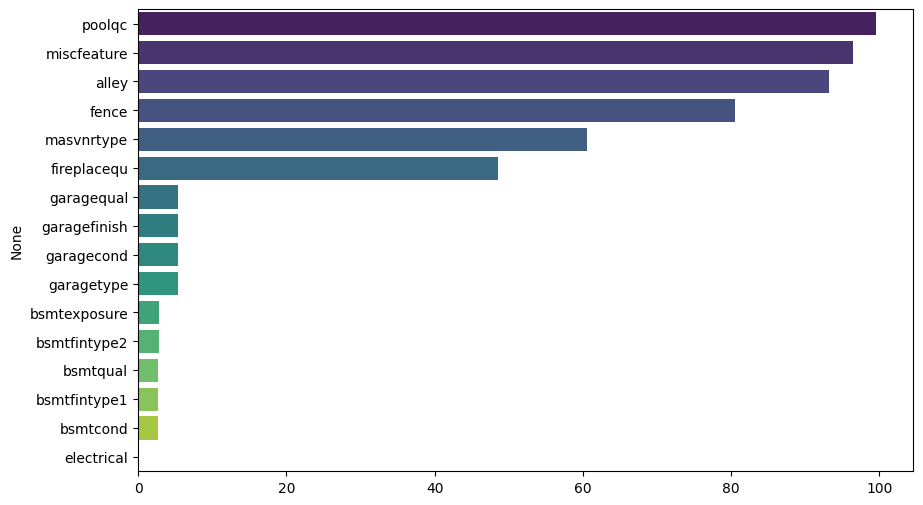

In [ ]:
fig,ax=plt.subplots(figsize=(10,6))
sns.barplot(x=null_columns_sorted.values,y=null_columns_sorted.index,palette='viridis')

 we have three main features that have nore than 80% missing features ['pool Qc','misc feature','alley','fence']
## Satrting studing them
and aplling missing techniques in them ['mar','mcar','mnar']


,poolqc
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
2925,NaN
2926,NaN
2927,NaN
2928,NaN


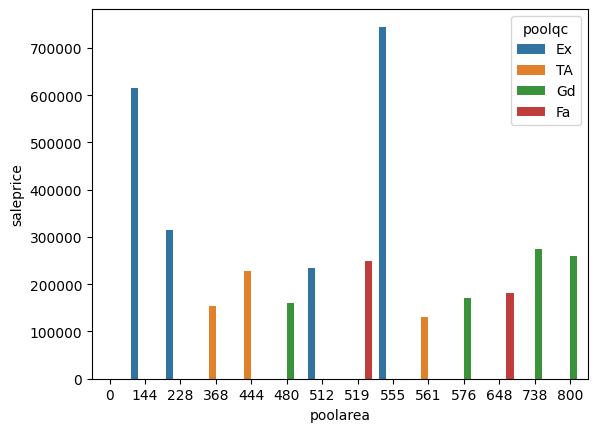

In [ ]:
df.poolqc.value_counts()
sns.barplot(x=df.poolarea,y=df.saleprice,hue=cat_df.poolqc)
pool_feeatures=df.filter(regex='poo')
pool_feeatures

df.poolqc.fillna(value='NaN')

<Axes: xlabel='poolqc', ylabel='saleprice'>

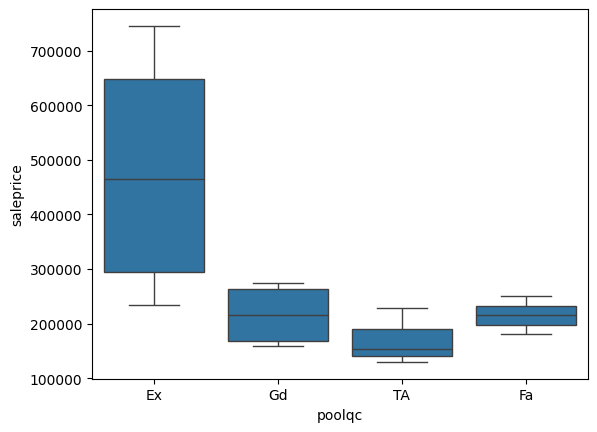

In [ ]:
sns.boxplot(x=cat_df.poolqc,y=df.saleprice)

## "We observed
that the average price of houses with a 'PoolQC' rating of 'TA' is higher than those rated 'Gd.' A deeper analysis revealed that this is due to data sparsity—only 7 houses in the entire dataset have swimming pools—as well as the influence of other key variables, such as the property's size and overall quality, We will not drop it in this stage beacouse his null values is missnig beacouse there are houses are not have pool "

,mszoning,street,alley,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,...,fireplacequ,garagetype,garagefinish,garagequal,garagecond,paveddrive,poolqc,fence,saletype,salecondition
0,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Gd,Attchd,Fin,TA,TA,P,NaN,NaN,WD,Normal
1,RH,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,...,NaN,Attchd,Unf,TA,TA,Y,NaN,MnPrv,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,NaN,WD,Normal
3,RL,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,NaN,WD,Normal
4,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,...,NaN,Detchd,Unf,TA,TA,Y,NaN,GdPrv,WD,Normal
2926,RL,Pave,NaN,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,MnPrv,WD,Normal
2927,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,...,NaN,NaN,NaN,NaN,NaN,Y,NaN,MnPrv,WD,Normal
2928,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,...,TA,Attchd,RFn,TA,TA,Y,NaN,NaN,WD,Normal


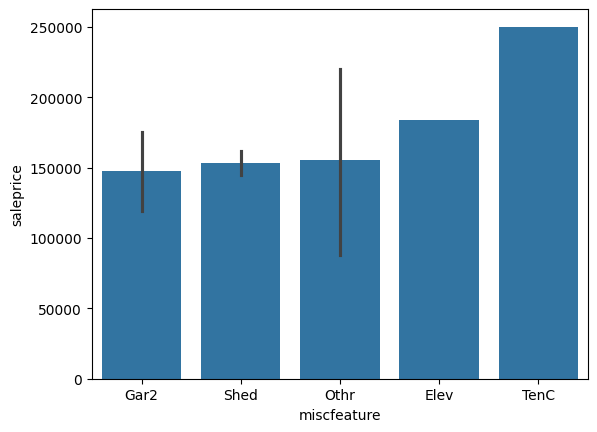

In [ ]:
df.miscfeature.value_counts()
sns.barplot(x=cat_df.miscfeature,y=df.saleprice)
cat_df.drop(['miscfeature'],axis=1,inplace=True)
cat_df

### Feature Analysis: `MiscFeature`

We decided to **drop** the `MiscFeature` column based on the following observations:

1. **Category Distribution & Dominance of `Shed`:** The feature contains only 4 categories. The vast majority of non-null values belong to `Shed`, which shows no meaningful influence on `SalePrice`.
2. **Rare Categories:** The remaining categories have an extremely small frequency in the data (only 1–2 occurrences), which introduces noise rather than useful signal.
3. **Feature Redundancy (`Gar2`):** Some categories, such as `Gar2` (second garage), represent redundant information that is already captured and handled by other garage-related features.

**Final Decision:** We will **drop** this feature because its useful information is already covered elsewhere, and its rare categories do not add predictive value.


/tmp/ipykernel_2675/2423696698.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.alley.fillna(value='NaN',inplace=True)


<Axes: xlabel='alley', ylabel='saleprice'>

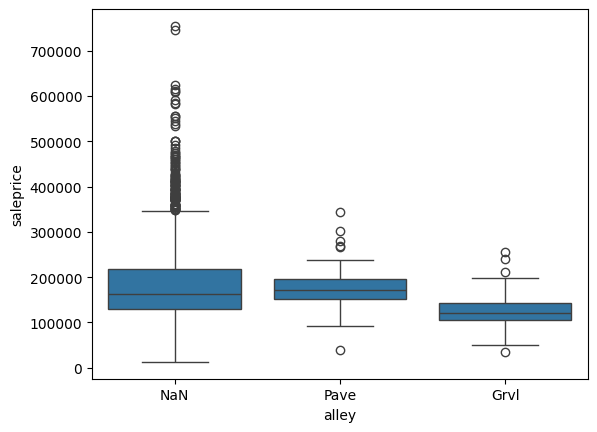

In [ ]:
df.alley.value_counts()
df.alley.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.alley,y=df.saleprice)

In [ ]:
cat_df.drop(['alley'],axis=1,inplace=True)
cat_df

,mszoning,street,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,...,fireplacequ,garagetype,garagefinish,garagequal,garagecond,paveddrive,poolqc,fence,saletype,salecondition
0,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Gd,Attchd,Fin,TA,TA,P,NaN,NaN,WD,Normal
1,RH,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,MnPrv,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,NaN,WD,Normal
3,RL,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,NaN,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,...,TA,Attchd,Fin,TA,TA,Y,NaN,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,...,NaN,Detchd,Unf,TA,TA,Y,NaN,GdPrv,WD,Normal
2926,RL,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,NaN,Attchd,Unf,TA,TA,Y,NaN,MnPrv,WD,Normal
2927,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,...,NaN,NaN,NaN,NaN,NaN,Y,NaN,MnPrv,WD,Normal
2928,RL,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,TA,Attchd,RFn,TA,TA,Y,NaN,NaN,WD,Normal


### Feature Analysis: `Alley`

Initially, we considered keeping the **`Alley`** feature because the boxplot showed a noticeable difference in median sale prices between the categories (`Pave` vs. `Grvl`).

However, after including the **`None`** category (properties without an alley) in the plot, we observed an apparent anomaly: the median price of homes with **no alley** was higher than those with a **gravel alley (`Grvl`)**.

Upon deeper investigation, we found that gravel alleys primarily indicate older, historic urban neighborhoods. This information is already well-captured by other stronger features in the dataset, such as `YearBuilt` and `Neighborhood`.

**Final Decision:**
We decided to **drop** the `Alley` feature. In addition to information redundancy, the primary driver is that **over 80% of the values are missing (severe imbalance)**, meaning it introduces unnecessary noise without adding significant new predictive value.

/tmp/ipykernel_2675/28258866.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['fence'].fillna('None', inplace=True)


<Axes: xlabel='fence', ylabel='saleprice'>

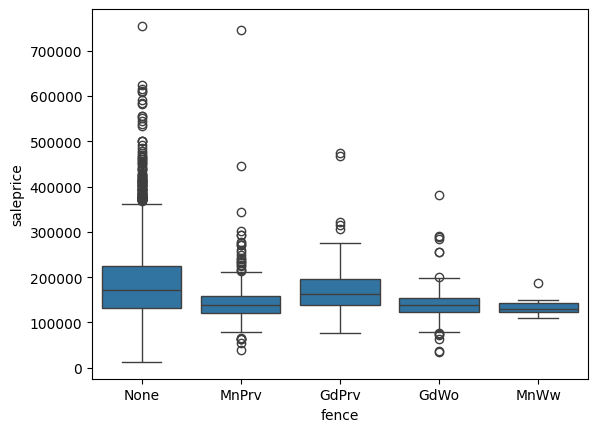

In [ ]:
df.fence.value_counts()
df['fence'].fillna('None', inplace=True)
sns.boxplot(data=df,x=df.fence,y=df.saleprice)

In [ ]:
cat_df.drop(['fence'],axis=1,inplace=True)
cat_df

,mszoning,street,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,...,functional,fireplacequ,garagetype,garagefinish,garagequal,garagecond,paveddrive,poolqc,saletype,salecondition
0,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Typ,Gd,Attchd,Fin,TA,TA,P,NaN,WD,Normal
1,RH,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,...,Typ,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Typ,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal
3,RL,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,...,Typ,NaN,Detchd,Unf,TA,TA,Y,NaN,WD,Normal
2926,RL,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,Typ,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal
2927,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,...,Typ,NaN,NaN,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,RL,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal


### Feature Analysis: `Fence`

We decided to **drop** the `Fence` feature for the following reasons:

1. **High Sparsity:** Over 80% of the properties do not have a fence (`NaN` / `None`).
2. **Counter-Intuitive Distribution:** Properties without fences exhibit a higher median sale price (~$170k) and account for almost all luxury outliers compared to properties with fences.
3. **Lack of Discriminative Power:** The various fence quality categories (`MnPrv`, `GdWo`, `MnWw`) show nearly identical price distributions (clustered around ~$135k), providing minimal predictive variance.

**Conclusion:** Dropping `Fence` reduces unnecessary dimensionality and avoids adding noise to the model.

/tmp/ipykernel_2675/3236565378.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['masvnrtype'].fillna(value='None',inplace=True)


,count
masvnrarea,
0.0,1748
120.0,15
176.0,13
200.0,13
180.0,12
...,...
293.0,1
653.0,1
630.0,1


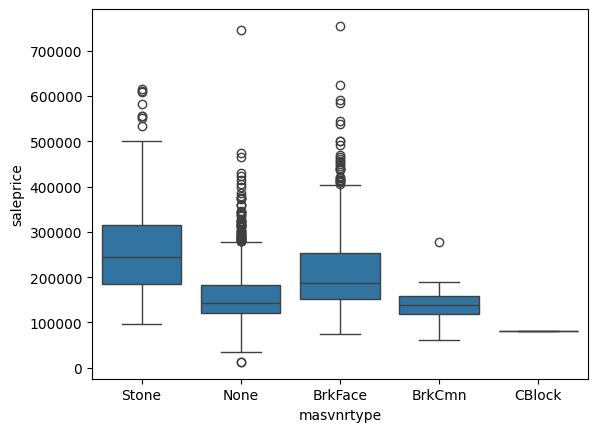

In [ ]:
df.masvnrtype.value_counts()
df['masvnrtype'].fillna(value='None',inplace=True)
sns.boxplot(data=df,x=df.masvnrtype,y=df.saleprice)
df.masvnrarea.value_counts()


### Feature Analysis: `MasVnrType`

**Decision:** **Retain (Keep)** the feature.

**Rationale:**
1. **Strong Price Discrimination:** The feature shows a clear and substantial impact on `SalePrice`. Properties with `Stone` masonry veneer have a median price (~$240k) significantly higher than `BrkFace` (~$185k) and properties with `None` (~$140k).
2. **Relationship with `MasVnrArea`:** This categorical feature captures the *material quality*, while `MasVnrArea` captures the *quantity*. This strong relationship will be leveraged in the Feature Engineering phase (e.g., interaction features or a binary `HasMasVnr` indicator).

**Conclusion:** Keeping `MasVnrType` preserves critical predictive variance for the regression model.

/tmp/ipykernel_2675/141839585.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.fireplacequ.fillna(value='NaN',inplace=True)


<Axes: xlabel='fireplacequ', ylabel='saleprice'>

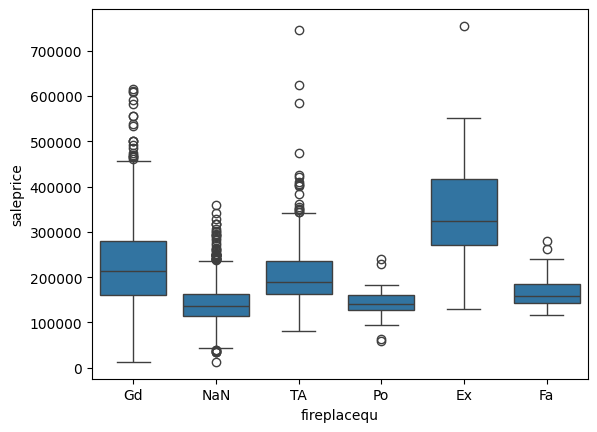

In [ ]:
df.fireplacequ.value_counts()
df.fireplacequ.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.fireplacequ,y=df.saleprice)

<Axes: xlabel='fireplaces', ylabel='saleprice'>

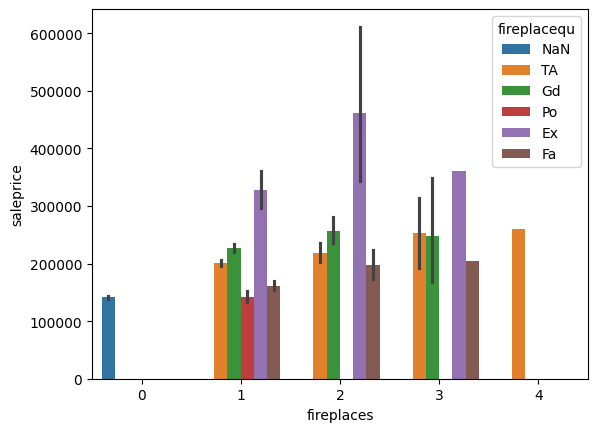

In [ ]:
sns.barplot(data=df,x=df.fireplaces,y=df.saleprice,hue=df.fireplacequ)

### Feature Analysis: `FireplaceQu` & `Fireplaces`

**Domain Insight (Geographic & Climate Context):**
Ames is located in Iowa, a Midwestern US state known for its harsh, freezing winters and heavy snowfall. In such cold climates, home heating amenities are not merely decorative—they serve a vital functional and comfort purpose. Consequently, the presence and quality of a fireplace significantly impact home buyer valuation and final `SalePrice`.

**Key Observations & Feature Interaction:**
1. **Strong Price Driver:** Homes with higher-quality fireplaces (`Ex`, `Gd`) consistently command a substantial price premium compared to homes with lower ratings or without fireplaces.
2. **Coupled Features:** `FireplaceQu` (quality) is directly tied to the numerical feature `Fireplaces` (count of fireplaces). When `Fireplaces == 0`, the property has no fireplace.
3. **Missing Value Nature (MNAR):** The `NA` (missing) values in `FireplaceQu` account for ~47% of the data and represent structural missingness (**Missing Not At Random - MNAR**)—meaning the home simply has **no fireplace**, rather than missing data.

**Preprocessing & Feature Engineering Strategy:**
* **Missing Value Imputation:** All `NaN` entries will be imputed with `'None'` (indicating the absence of a fireplace).
* **Encoding Technique (Ordinal Encoding):** Because fireplace quality possesses a clear inherent hierarchy, we will apply **Ordinal Encoding** rather than One-Hot Encoding. This preserves the natural rank order while preventing unnecessary dimensionality expansion:
  $$\text{None} (0) < \text{Po} (1) < \text{Fa} (2) < \text{TA} (3) < \text{Gd} (4) < \text{Ex} (5)$$

**Conclusion:** Retaining and ordinally encoding `FireplaceQu` alongside `Fireplaces` preserves one of the most critical predictive signals in the dataset.

/tmp/ipykernel_2675/4277113581.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.garagequal.fillna(value='NaN',inplace=True)


<Axes: xlabel='garagequal', ylabel='saleprice'>

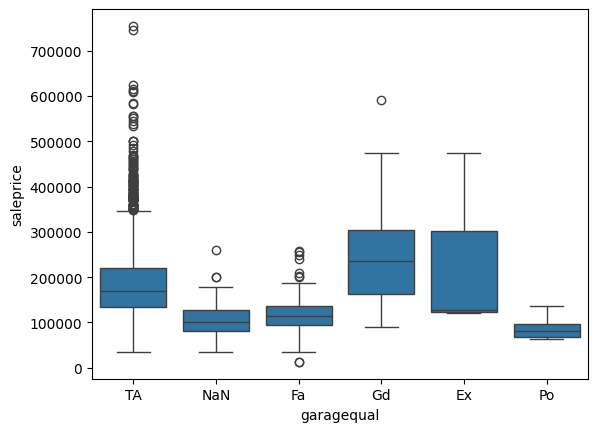

In [ ]:
df.garagequal.value_counts()
df.garagequal.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.garagequal,y=df.saleprice)

/tmp/ipykernel_2675/181043340.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.garagefinish.fillna(value='NaN',inplace=True)


<Axes: xlabel='garagefinish', ylabel='saleprice'>

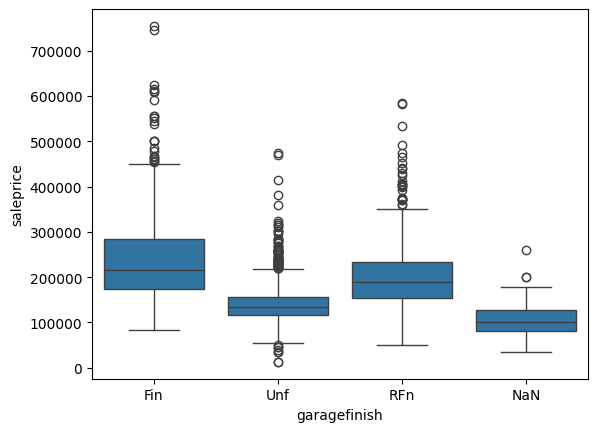

In [ ]:
df.garagefinish.value_counts()
df.garagefinish.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.garagefinish,y=df.saleprice)

/tmp/ipykernel_2675/4209726128.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.garagetype.fillna(value='NaN',inplace=True)


<Axes: xlabel='garagetype', ylabel='saleprice'>

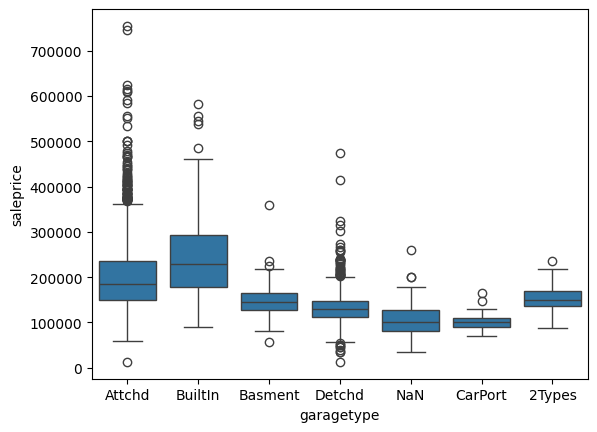

In [ ]:
df.garagetype.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.garagetype,y=df.saleprice)

/tmp/ipykernel_2675/1442090253.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.garagecond.fillna(value='NaN',inplace=True)


<Axes: xlabel='garagecond', ylabel='saleprice'>

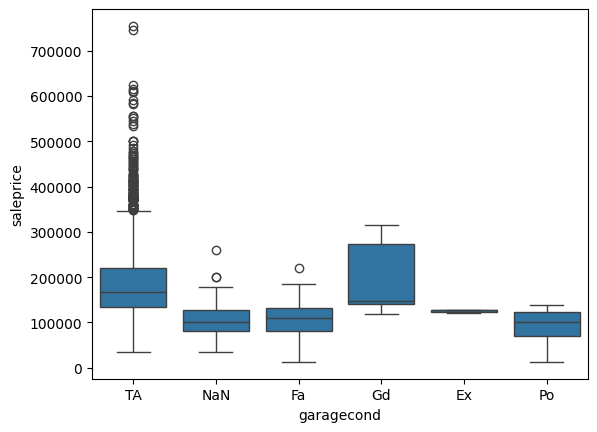

In [ ]:
df.garagecond.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.garagecond,y=df.saleprice)

In [ ]:
garage_cols = ['garagequal', 'garagefinish', 'garagetype', 'garagecond']

results = df[garage_cols + ['saleprice']].melt(
    id_vars='saleprice',
    var_name='garage_feature',
    value_name='category'
).groupby(['garage_feature', 'category']).agg(
    saleprice_mean=('saleprice', 'mean')
)

results


saleprice_mean
garage_feature category                
garagecond     Ex         125000.000000
               Fa         107492.351351
               Gd         194058.000000
               NaN        105584.540881
               Po          94850.000000
               TA         187758.465291
garagefinish   Fin        239820.456044
               NaN        105584.540881
               RFn        202619.366995
               Unf        141209.013810
garagequal     Ex         241000.000000
               Fa         117816.822581
               Gd         243772.375000
               NaN        105584.540881
               Po          88880.000000
               TA         187884.241300
garagetype     2Types     154639.130435
               Attchd     203772.283651
               Basment    150473.416667
               BuiltIn    249344.150538
               CarPort    105566.666667
               Detchd     132468.471867
               NaN        104949.254777

In [ ]:
cat_df.drop(['garagequal','garagecond'],axis=1,inplace=True)
cat_df

,mszoning,street,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,...,electrical,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,SBrkr,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,RH,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,...,SBrkr,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,SBrkr,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,RL,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,SBrkr,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,...,SBrkr,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,RL,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,RL,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


### Comprehensive Feature Analysis: Garage Categorical Features
(`GarageQual`, `GarageCond`, `GarageFinish`, `GarageType`)

Through group-level exploratory data analysis (`groupby`), we analyzed the mean sale prices across all four garage categorical features.
A key baseline finding is that properties with no garage (`NaN`) consistently exhibit a substantially lower average price of **~$105,584** across all four features, representing the fundamental baseline penalty for lacking a garage.

---

#### 1. Decision: DROP `GarageQual` & `GarageCond`
* **Extreme Dominance & Near-Zero Variance:** Both features are overwhelmingly dominated by a single category (`TA`), which accounts for ~90% of the non-null records (average price ~$187k).
* **Multicollinearity & Redundancy:** These two columns are near-duplicates of each other (~99% correlation) and provide virtually no variance to distinguish properties.
* **Captured Numerically:** The baseline impact of having a garage is already accurately captured by numerical attributes (`GarageCars` and `GarageArea`).
* **Conclusion:** Both `GarageQual` and `GarageCond` are **dropped** to eliminate redundant dimensions and prevent overfitting on sparse non-TA categories.

---

#### 2. Decision: RETAIN `GarageFinish` & `GarageType`
Unlike quality/condition, these two features reveal massive price stratification *among properties that already have a garage*:
* **`GarageFinish` (Finish Quality):** Exhibits a clear monotonic price progression:
  * **Unfinished (`Unf`):** Mean price = **$141,209**
  * **Rough Finished (`RFn`):** Mean price = **$202,619**
  * **Finished (`Fin`):** Mean price = **$239,820**
  * *Insight:* A **~$100,000 price spread** exists purely based on the interior finish of the garage, serving as a powerful proxy for overall house luxury.
  * *Encoding:* Will be **Ordinally Encoded**: $\text{None} (0) < \text{Unf} (1) < \text{RFn} (2) < \text{Fin} (3)$.
* **`GarageType` (Architectural Placement):** Clearly separates historic detached garages (`Detchd` @ ~$132k) from modern high-end attached/integrated structures (`BuiltIn` @ ~$249k).
  * *Encoding:* Will be **One-Hot Encoded**.

---

#### 3. Planned Feature Engineering: Create `HasGarage`
To explicitly isolate the baseline presence effect (~$105k vs. ~$187k+) without relying on noisy categorical levels, we will create a clean binary indicator:
$$\text{HasGarage} = \begin{cases} 0, & \text{if GarageArea} == 0 \text{ (or NaN)} \\ 1, & \text{otherwise} \end{cases}$$

**Summary:** This selective strategy eliminates redundant noise (`GarageQual`, `GarageCond`), retains high-value predictive signals (`GarageFinish`, `GarageType`), and isolates structural absence via `HasGarage`.

/tmp/ipykernel_2675/3151997584.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.bsmtexposure.fillna(value='NaN',inplace=True)


<Axes: xlabel='bsmtexposure', ylabel='saleprice'>

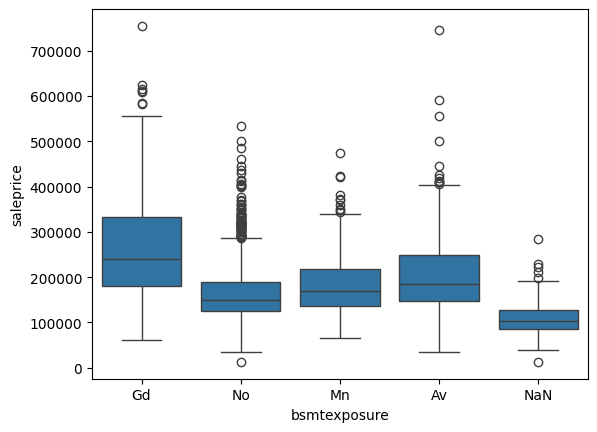

In [ ]:
df.bsmtexposure.value_counts()
df.bsmtexposure.fillna(value='NaN',inplace=True)
sns.boxplot(data=df,x=df.bsmtexposure,y=df.saleprice)

In [ ]:
df.bsmtfintype1.value_counts()
# df.bsmtfintype2.value_counts()
# df.bsmtcond.value_counts()
# df.bsmtqual.value_counts()

,count
bsmtfintype1,
GLQ,859
Unf,851
ALQ,429
Rec,288
BLQ,269
LwQ,154


<Axes: xlabel='bsmtqual', ylabel='saleprice'>

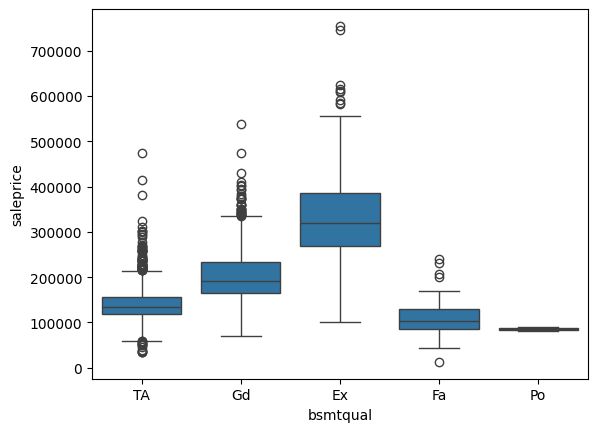

In [ ]:
df.groupby('bsmtqual')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)
sns.boxplot(data=df,x=df.bsmtqual,y=df.saleprice)

In [ ]:
df.groupby('bsmtqual')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
bsmtqual,,,,
Ex,258,333369.313953,320000.0,105075.027197
Fa,88,109635.238636,102500.0,38327.178357
Gd,1219,201726.765381,192000.0,56611.302954
Po,2,84950.000000,84950.0,5727.564928
TA,1283,139847.394388,135000.0,40581.464727


In [ ]:
df.groupby('bsmtfintype1')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
bsmtfintype1,,,,
ALQ,429,163012.920746,151000.0,48791.908390
BLQ,269,150084.182156,140000.0,46768.055259
GLQ,859,237265.857974,215000.0,92283.399492
LwQ,154,152191.077922,138450.0,54127.216139
Rec,288,142774.138889,136250.0,48740.400261
Unf,851,167430.411281,158500.0,70878.816000


In [ ]:
df.groupby('bsmtcond')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
bsmtcond,,,,
Ex,3,195000.000000,160000.0,83216.584885
Fa,104,123315.480769,116750.0,49252.754259
Gd,122,214604.303279,193939.5,74956.640089
Po,5,124063.200000,94550.0,84898.940048
TA,2616,183847.235092,164250.0,79767.371538


In [ ]:
cat_df.drop(['bsmtcond','bsmtcond','bsmtfintype2','bsmtexposure'],axis=1,inplace=True)
cat_df

,mszoning,street,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,...,electrical,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,SBrkr,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,RH,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,...,SBrkr,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,SBrkr,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,RL,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,SBrkr,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,...,SBrkr,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,RL,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,RL,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,SBrkr,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


### Feature Removal Justification — Basement Features

The following features were removed based on preliminary exploratory data analysis (EDA):

- **`BsmtCond`**: Removed because most observations fall into the `TA` category, while some categories, such as `Ex` and `Po`, have very few observations. This makes comparisons for the rare categories unreliable, and the feature's additional predictive value remains uncertain.

- **`BsmtFinType2`**: Removed because it describes the type of finish in the second finished basement area, which may provide limited additional information compared with other basement-related features. Its incremental predictive value has not yet been established.

- **`BsmtExposure`**: Removed as a preliminary feature-selection decision because its additional contribution to predicting `SalePrice` has not been confirmed. Other property characteristics may capture some overlapping information.

**Note:** These removals are preliminary decisions based on EDA and feature-redundancy hypotheses, not proof that the features are useless. Their impact should be evaluated by comparing cross-validation performance before and after removal.

<Axes: xlabel='electrical', ylabel='saleprice'>

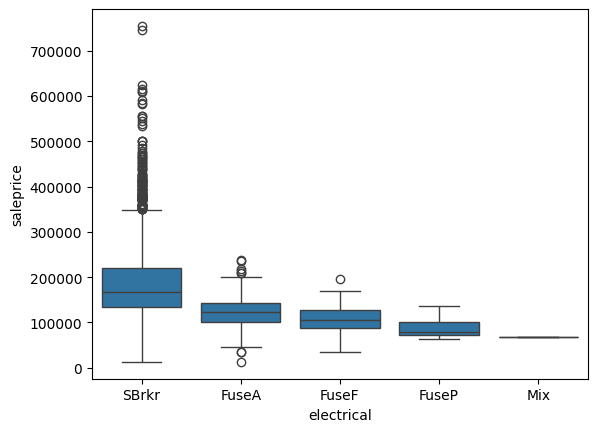

In [ ]:
df.electrical.value_counts()
sns.boxplot(data=df,x=df.electrical,y=df.saleprice)

In [ ]:
df.groupby('electrical')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
electrical,,,,
FuseA,188,122264.079787,123750.0,37708.162231
FuseF,50,105718.240000,106000.0,30789.150772
FuseP,8,90175.000000,78500.0,28093.250333
Mix,1,67000.000000,67000.0,NaN
SBrkr,2682,186616.329978,167870.0,80280.808502


In [ ]:
cat_df.drop(['electrical'],axis=1,inplace=True)
cat_df

,mszoning,street,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,RH,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,RL,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,RL,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,RL,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


### Electrical Feature Removal

I decided to remove the `Electrical` feature because approximately 90% of the observations belong to the `SBrkr` category, making the feature highly imbalanced. In addition, the differences in mean `SalePrice` between the categories are relatively small, suggesting a weak relationship between the electrical system type and the target variable.

Since almost all houses have the same electrical system category, this feature may provide limited predictive information and may not contribute significantly to the model's performance.

## Finshed working on features has null values and have missing data
starting working in Remaining features

In [ ]:
df.mszoning.value_counts()

,count
mszoning,
RL,2273
RM,462
FV,139
RH,27
C (all),25
I (all),2
A (agr),2


In [ ]:
df.groupby('mszoning')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
mszoning,,,,
A (agr),2,47300.000000,47300.0,48366.103833
C (all),25,79795.040000,78000.0,31084.817206
FV,139,218986.949640,209000.0,52684.229037
I (all),2,80312.500000,80312.5,32084.970196
RH,27,136419.777778,140000.0,36173.101244
RL,2273,191283.251650,172000.0,81295.736203
RM,462,126781.393939,120750.0,48145.542821


In [ ]:
cat_df.drop(['mszoning'],axis=1,inplace=True)
cat_df

,street,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,bldgtype,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,1Fam,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


### MSZoning Feature Removal

I decided to remove the `MSZoning` feature because, although the differences in mean `SalePrice` between categories suggest a relationship with the target variable, some categories contain very few observations. For example, `A (agr)` and `I (all)` have only 2 observations each, while `C (all)` has only 25, compared with 2,273 observations in `RL`.

These differences in mean prices may be misleading because the estimates for categories with very few observations are not reliable enough to represent their actual price distributions.

From a Linear Regression perspective, when `MSZoning` is encoded using One-Hot Encoding, the model can learn a separate coefficient for each category. However, categories with very few observations provide limited information for estimating these coefficients reliably. As a result, the model may not generalize well to unseen houses belonging to these rare categories, especially when their prices differ significantly from those of the dominant category.

Therefore, I decided to remove `MSZoning` as a preliminary feature-selection decision because the limited representation of some categories may make their learned effects unreliable. This decision is based on the current EDA findings and should ideally be validated by comparing model performance with and without the feature.

In [ ]:
df.street.value_counts()

,count
street,
Pave,2918
Grvl,12


### Street Feature Removal

I decided to remove the `Street` feature because its distribution is highly imbalanced: approximately 99.6% of the observations belong to the `Pave` category, while only 12 observations belong to `Grvl`.

This means the feature provides very limited variation across the dataset, with almost all houses sharing the same street type. Consequently, the model may gain limited predictive information from this feature, while the rare `Grvl` category may not contain enough observations for its effect on `SalePrice` to be estimated reliably.

Although street type could potentially influence house prices, I decided to exclude this feature as a preliminary feature-selection decision because its additional predictive value has not yet been established.


In [ ]:
cat_df.drop(['street'],axis=1,inplace=True)
cat_df

,lotshape,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,bldgtype,housestyle,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,IR1,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,Reg,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


In [ ]:
df.lotshape.value_counts()

,count
lotshape,
Reg,1859
IR1,979
IR2,76
IR3,16


In [ ]:
df.groupby('lotshape')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
lotshape,,,,
IR1,979,210925.348315,190000.0,85257.984465
IR2,76,229588.355263,213000.0,88988.692020
IR3,16,221922.812500,213000.0,87539.461539
Reg,1859,162580.451856,145000.0,70218.483902


<Axes: xlabel='lotshape', ylabel='saleprice'>

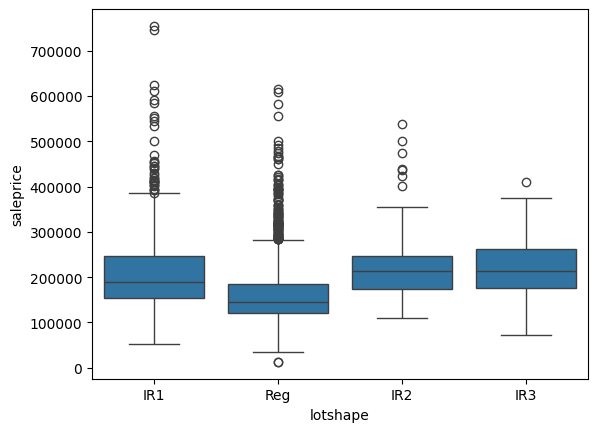

In [ ]:
sns.boxplot(data=df,x=df.lotshape,y=df.saleprice)

### LotShape Feature Removal

I decided to remove the `LotShape` feature because the exploratory data analysis showed that its relationship with `SalePrice` was not straightforward. Although regular-shaped lots (`Reg`) might be expected to have an advantage, their mean sale price was noticeably lower than those of the irregular categories.

Additionally, the mean prices of `IR1`, `IR2`, and `IR3` were relatively close compared with the large variation in prices within each category. This suggests that lot shape alone may not provide a strong or consistent explanation for house prices, and other features, such as lot area, overall quality, and location, may be more informative.

Therefore, I excluded `LotShape` as a preliminary feature-selection decision because its additional predictive contribution was not sufficiently clear from the descriptive statistics and boxplot.

In [ ]:
cat_df.drop(['lotshape'],axis=1,inplace=True)
cat_df

,landcontour,utilities,lotconfig,landslope,neighborhood,condition1,condition2,bldgtype,housestyle,roofstyle,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,Gable,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,Gable,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Lvl,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,Gable,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,Gable,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,Lvl,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


In [ ]:
df.landcontour.value_counts()

,count
landcontour,
Lvl,2633
HLS,120
Bnk,117
Low,60


In [ ]:
df.groupby('landcontour')['saleprice'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
landcontour,,,,
Bnk,117,144754.589744,136500.0,51441.306340
HLS,120,253924.525000,232606.5,117631.791196
Low,60,194882.733333,187750.0,80519.514279
Lvl,2633,178743.737942,160000.0,76838.447463


<Axes: xlabel='lotshape', ylabel='saleprice'>

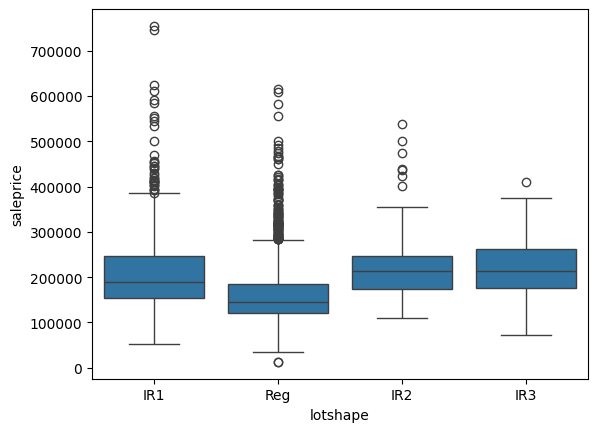

In [ ]:
sns.boxplot(data=df,x=df.lotshape,y=df.saleprice)

### LandContour Feature Removal

I decided to remove the `LandContour` feature because the `Lvl` category dominates the dataset, with 2,633 observations, leaving relatively few samples in the other categories.

Additionally, the boxplot showed relatively similar sale-price distributions across the categories, suggesting that land contour may have a limited relationship with `SalePrice` in this dataset. Since most properties share the same contour type and the differences between categories appear limited, I consider this feature less informative than other property characteristics.

Therefore, I removed `LandContour` as a preliminary feature-selection decision based on category distribution and exploratory analysis of sale prices.

In [ ]:
cat_df.drop(['landcontour'],axis=1,inplace=True)
cat_df

,utilities,lotconfig,landslope,neighborhood,condition1,condition2,bldgtype,housestyle,roofstyle,roofmatl,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,Gable,CompShg,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,Gable,CompShg,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,AllPub,CulDSac,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,Gable,CompShg,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,Gable,CompShg,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,AllPub,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


In [ ]:
df.utilities.value_counts()

,count
utilities,
AllPub,2927
NoSewr,2
NoSeWa,1


<Axes: xlabel='utilities', ylabel='Count'>

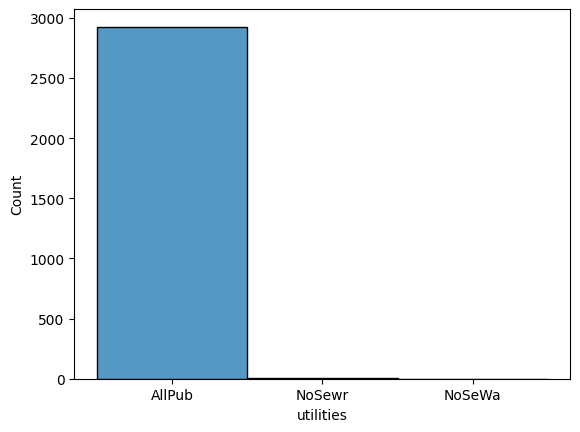

In [ ]:
sns.histplot(data=df,x=df.utilities)

### Utilities Feature Removal

I decided to remove the `Utilities` feature because its distribution is extremely imbalanced. The `AllPub` category accounts for 2,927 observations out of 2,930, representing approximately 99.9% of the dataset, while `NoSewr` appears only twice and `NoSeWa` only once.

As observed in the category distribution plot, almost all properties share the same utilities classification. Therefore, this feature provides very little variation across the dataset, and the rare categories have too few observations for the model to learn their effects reliably.

Consequently, I decided to exclude `Utilities` because it is unlikely to provide substantial additional predictive information, based on the current EDA findings.

In [ ]:
cat_df.drop(['utilities'],axis=1,inplace=True)
cat_df

,lotconfig,landslope,neighborhood,condition1,condition2,bldgtype,housestyle,roofstyle,roofmatl,exterior1st,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,Gable,CompShg,VinylSd,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,Wd Sdng,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,CulDSac,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,Gable,CompShg,HdBoard,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,HdBoard,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,Inside,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,Gable,CompShg,HdBoard,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,Inside,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,HdBoard,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


In [ ]:
df.lotconfig.value_counts()

,count
lotconfig,
Inside,2140
Corner,511
CulDSac,180
FR2,85
FR3,14


In [ ]:
df.groupby('lotconfig')['saleprice'].agg(
    ['count','mean','median','std']
)

,count,mean,median,std
lotconfig,,,,
Corner,511,179956.937378,160000.0,81104.689293
CulDSac,180,225531.872222,206750.0,98164.169218
FR2,85,174122.894118,160500.0,58779.791476
FR3,14,196635.857143,184450.0,78397.476413
Inside,2140,177395.035514,158000.0,77508.305293


<Axes: xlabel='lotconfig', ylabel='saleprice'>

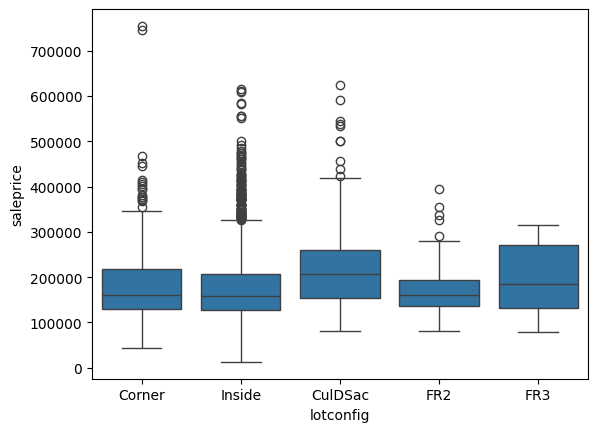

In [ ]:
sns.boxplot(data=df,x=df.lotconfig,y=df.saleprice)

**Reason for Removal:**

The feature was removed as a preliminary feature-selection decision based on exploratory data analysis (EDA). The data is highly imbalanced, with most observations concentrated in a single category. In addition, the mean SalePrice values across the categories are relatively close to each other, while the price distributions show high variability within each category. This makes it difficult to distinguish the effect of the feature on SalePrice based on the current analysis.

The feature may still contain useful predictive information, so its removal should ideally be validated by comparing model performance before and after removal using cross-validation.

In [ ]:
cat_df.drop(['lotconfig'],axis=1,inplace=True)
cat_df

,landslope,neighborhood,condition1,condition2,bldgtype,housestyle,roofstyle,roofmatl,exterior1st,exterior2nd,...,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc,saletype,salecondition
0,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,Plywood,...,Y,TA,Typ,Gd,Attchd,Fin,P,NaN,WD,Normal
1,Gtl,NAmes,Feedr,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,Wd Sdng,Wd Sdng,...,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
3,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,BrkFace,...,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
4,Gtl,Gilbert,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,VinylSd,...,Y,TA,Typ,TA,Attchd,Fin,Y,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,Gable,CompShg,HdBoard,HdBoard,...,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN,WD,Normal
2926,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,HdBoard,HdBoard,...,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN,WD,Normal
2927,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,Gable,CompShg,HdBoard,Wd Shng,...,Y,TA,Typ,NaN,NaN,NaN,Y,NaN,WD,Normal
2928,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,HdBoard,HdBoard,...,Y,TA,Typ,TA,Attchd,RFn,Y,NaN,WD,Normal


In [ ]:
df.saletype.value_counts()
df.salecondition.value_counts()

,count
salecondition,
Normal,2413
Partial,245
Abnorml,190
Family,46
Alloca,24
AdjLand,12


**Reason for Removal:**

Both `SaleType` and `SaleCondition` were removed as preliminary feature-selection decisions based on exploratory data analysis (EDA). The distributions show limited diversity, with most observations concentrated in a few categories and relatively few samples in the remaining categories. Additionally, based on the initial analysis and domain assumptions, these features were considered less informative for predicting `SalePrice` compared with other property characteristics.

However, sale type and sale condition may still influence property prices, so their removal should ideally be validated by comparing model performance before and after removal using cross-validation.

In [ ]:
cat_df.drop(['saletype','salecondition'],axis=True,inplace=True)
cat_df

,landslope,neighborhood,condition1,condition2,bldgtype,housestyle,roofstyle,roofmatl,exterior1st,exterior2nd,...,heating,heatingqc,centralair,kitchenqual,functional,fireplacequ,garagetype,garagefinish,paveddrive,poolqc
0,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,Plywood,...,GasA,Fa,Y,TA,Typ,Gd,Attchd,Fin,P,NaN
1,Gtl,NAmes,Feedr,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,...,GasA,TA,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN
2,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,Wd Sdng,Wd Sdng,...,GasA,TA,Y,Gd,Typ,NaN,Attchd,Unf,Y,NaN
3,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,BrkFace,...,GasA,Ex,Y,Ex,Typ,TA,Attchd,Fin,Y,NaN
4,Gtl,Gilbert,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,VinylSd,...,GasA,Gd,Y,TA,Typ,TA,Attchd,Fin,Y,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,Gable,CompShg,HdBoard,HdBoard,...,GasA,TA,Y,TA,Typ,NaN,Detchd,Unf,Y,NaN
2926,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,HdBoard,HdBoard,...,GasA,TA,Y,TA,Typ,NaN,Attchd,Unf,Y,NaN
2927,Gtl,Mitchel,Norm,Norm,1Fam,SFoyer,Gable,CompShg,HdBoard,Wd Shng,...,GasA,TA,Y,TA,Typ,NaN,NaN,NaN,Y,NaN
2928,Mod,Mitchel,Norm,Norm,1Fam,1Story,Gable,CompShg,HdBoard,HdBoard,...,GasA,Gd,Y,TA,Typ,TA,Attchd,RFn,Y,NaN


In [ ]:
df.landslope.value_counts()
df.condition1.value_counts()
df.condition2.value_counts()
df.bldgtype.value_counts()
df.roofstyle.value_counts()
df.roofmatl.value_counts()
df.heating.value_counts()
df.centralair.value_counts()
df.kitchenabvgr.value_counts()


,count
kitchenabvgr,
1,2796
2,129
0,3
3,2


/tmp/ipykernel_2675/2654801288.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/2654801288.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/2654801288.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/2654801288.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2

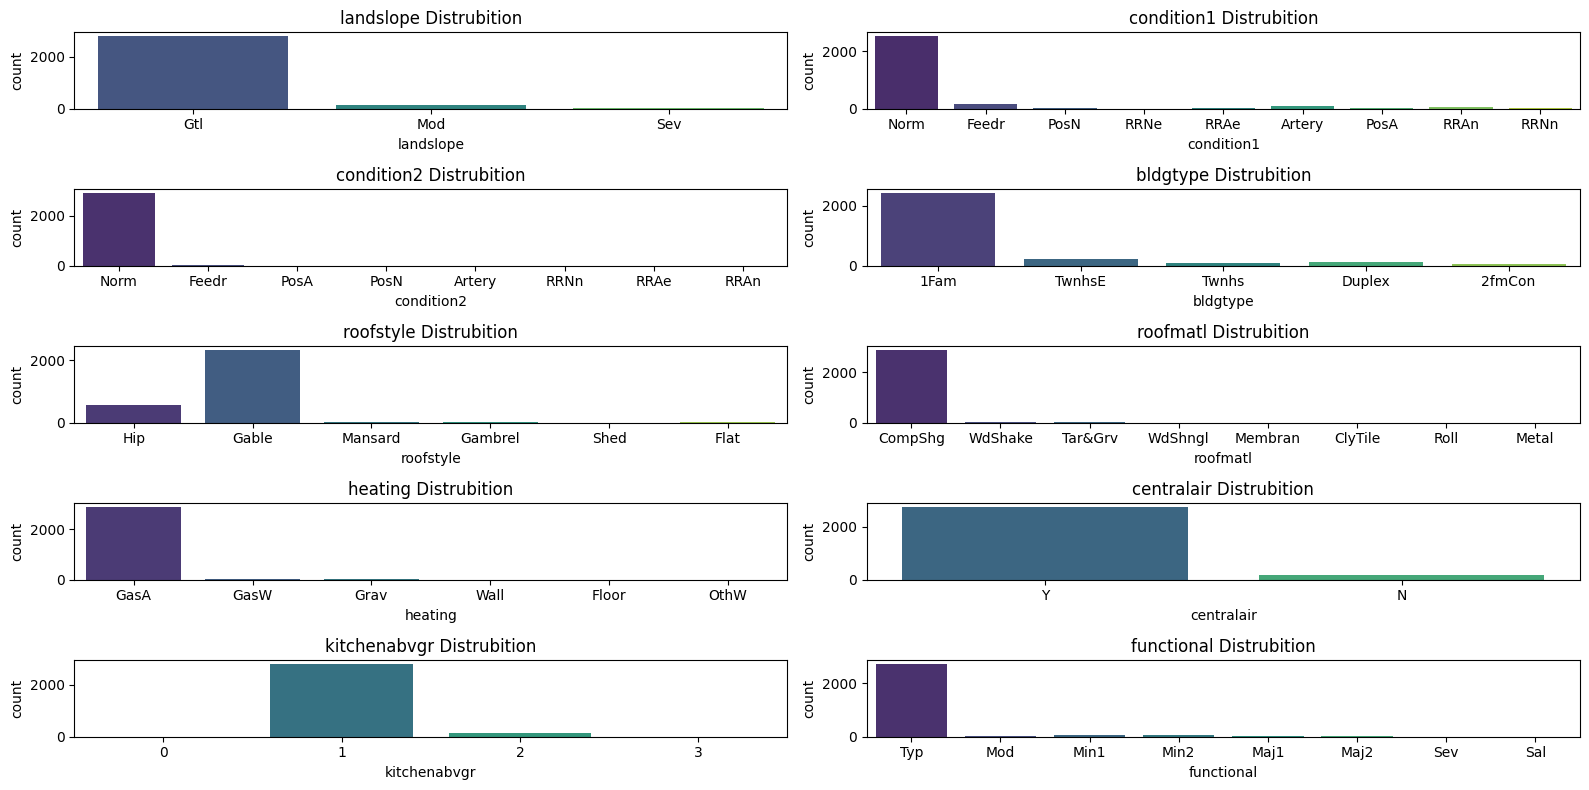

In [ ]:
import math
columns = [
    'landslope', 'condition1', 'condition2', 'bldgtype',
    'roofstyle', 'roofmatl', 'heating', 'centralair',
    'kitchenabvgr', 'functional'
]
n_of_subplotcol=2
n_of_subplotRows=math.ceil(len(columns) / n_of_subplotcol)

fig,ax=plt.subplots(n_of_subplotRows,n_of_subplotcol,
                    figsize=(16,n_of_subplotcol*4)
                    )

ax=ax.flatten()

for i  , col in enumerate(columns):
    sns.countplot(data=df,
                  x=col,
                  ax=ax[i] ,
                   palette='viridis' )
    ax[i].set_title(f'{col} Distrubition')

plt.tight_layout()
plt.show()


**Reason for Removal:**

A preliminary analysis of these categorical features revealed that their distributions were concentrated in a limited number of categories. Based on this initial observation, these features were selected for removal to simplify the dataset and reduce the number of categorical variables considered during modeling.

This decision was based on a quick exploratory analysis rather than a confirmed lack of predictive value. Some of these features may still influence `SalePrice`, so their removal could be reconsidered if model evaluation indicates that they provide useful information.

In [ ]:
cat_df.drop([
    'landslope', 'condition1', 'condition2', 'bldgtype',
    'roofstyle', 'roofmatl', 'heating', 'centralair', 'functional'
],axis=1,inplace=True)
cat_df

,neighborhood,housestyle,exterior1st,exterior2nd,masvnrtype,exterqual,extercond,foundation,bsmtqual,bsmtfintype1,heatingqc,kitchenqual,fireplacequ,garagetype,garagefinish,paveddrive,poolqc
0,NAmes,1Story,BrkFace,Plywood,Stone,TA,TA,CBlock,TA,BLQ,Fa,TA,Gd,Attchd,Fin,P,NaN
1,NAmes,1Story,VinylSd,VinylSd,NaN,TA,TA,CBlock,TA,Rec,TA,TA,NaN,Attchd,Unf,Y,NaN
2,NAmes,1Story,Wd Sdng,Wd Sdng,BrkFace,TA,TA,CBlock,TA,ALQ,TA,Gd,NaN,Attchd,Unf,Y,NaN
3,NAmes,1Story,BrkFace,BrkFace,NaN,Gd,TA,CBlock,TA,ALQ,Ex,Ex,TA,Attchd,Fin,Y,NaN
4,Gilbert,2Story,VinylSd,VinylSd,NaN,TA,TA,PConc,Gd,GLQ,Gd,TA,TA,Attchd,Fin,Y,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Mitchel,SLvl,HdBoard,HdBoard,NaN,TA,TA,CBlock,TA,GLQ,TA,TA,NaN,Detchd,Unf,Y,NaN
2926,Mitchel,1Story,HdBoard,HdBoard,NaN,TA,TA,CBlock,Gd,BLQ,TA,TA,NaN,Attchd,Unf,Y,NaN
2927,Mitchel,SFoyer,HdBoard,Wd Shng,NaN,TA,TA,PConc,Gd,GLQ,TA,TA,NaN,NaN,NaN,Y,NaN
2928,Mitchel,1Story,HdBoard,HdBoard,NaN,TA,TA,CBlock,Gd,ALQ,Gd,TA,TA,Attchd,RFn,Y,NaN


## columns_to_study
['neighborhood','housestyle','exterior1st','exterior2nd','masvnrtype','exterqual','extercond','foundation']

/tmp/ipykernel_2675/886984608.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/886984608.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/886984608.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/886984608.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,
/tmp/ipykernel_2675/8869

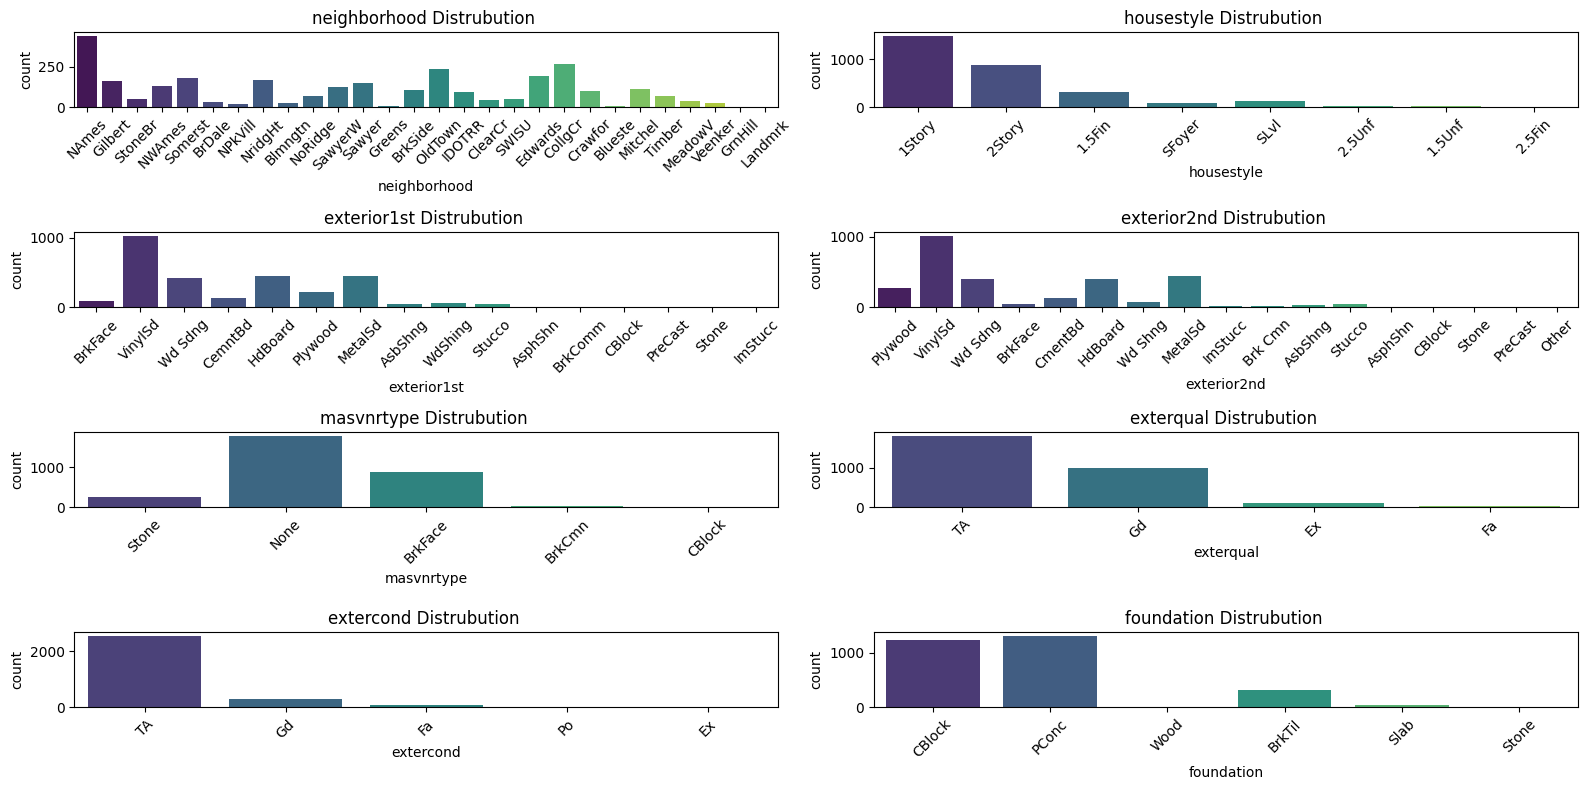

In [ ]:
columns_to_study=['neighborhood','housestyle','exterior1st','exterior2nd','masvnrtype','exterqual','extercond','foundation']
nfcol=2
nfrows=math.ceil(len(columns_to_study)/nfcol)
fig,ax=plt.subplots(nfrows,nfcol,
                    figsize=(16,nfcol*4))
ax=ax.flatten()
for i,col in enumerate(columns_to_study):
    sns.countplot(data=df,
                x=col,
                ax=ax[i],
                palette='viridis'
                )
    ax[i].set_title(f"{col} Distrubution ")
    ax[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## we will drop extracond

In [ ]:
cat_df.drop('extercond',axis=1,inplace=True)
cat_df

,neighborhood,housestyle,exterior1st,exterior2nd,masvnrtype,exterqual,foundation,bsmtqual,bsmtfintype1,heatingqc,kitchenqual,fireplacequ,garagetype,garagefinish,paveddrive,poolqc
0,NAmes,1Story,BrkFace,Plywood,Stone,TA,CBlock,TA,BLQ,Fa,TA,Gd,Attchd,Fin,P,NaN
1,NAmes,1Story,VinylSd,VinylSd,NaN,TA,CBlock,TA,Rec,TA,TA,NaN,Attchd,Unf,Y,NaN
2,NAmes,1Story,Wd Sdng,Wd Sdng,BrkFace,TA,CBlock,TA,ALQ,TA,Gd,NaN,Attchd,Unf,Y,NaN
3,NAmes,1Story,BrkFace,BrkFace,NaN,Gd,CBlock,TA,ALQ,Ex,Ex,TA,Attchd,Fin,Y,NaN
4,Gilbert,2Story,VinylSd,VinylSd,NaN,TA,PConc,Gd,GLQ,Gd,TA,TA,Attchd,Fin,Y,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Mitchel,SLvl,HdBoard,HdBoard,NaN,TA,CBlock,TA,GLQ,TA,TA,NaN,Detchd,Unf,Y,NaN
2926,Mitchel,1Story,HdBoard,HdBoard,NaN,TA,CBlock,Gd,BLQ,TA,TA,NaN,Attchd,Unf,Y,NaN
2927,Mitchel,SFoyer,HdBoard,Wd Shng,NaN,TA,PConc,Gd,GLQ,TA,TA,NaN,NaN,NaN,Y,NaN
2928,Mitchel,1Story,HdBoard,HdBoard,NaN,TA,CBlock,Gd,ALQ,Gd,TA,TA,Attchd,RFn,Y,NaN


/tmp/ipykernel_2675/533943049.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,
/tmp/ipykernel_2675/533943049.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,
/tmp/ipykernel_2675/533943049.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,
/tmp/ipykernel_2675/533943049.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,
/tmp/ipykernel_2675/533943049.py

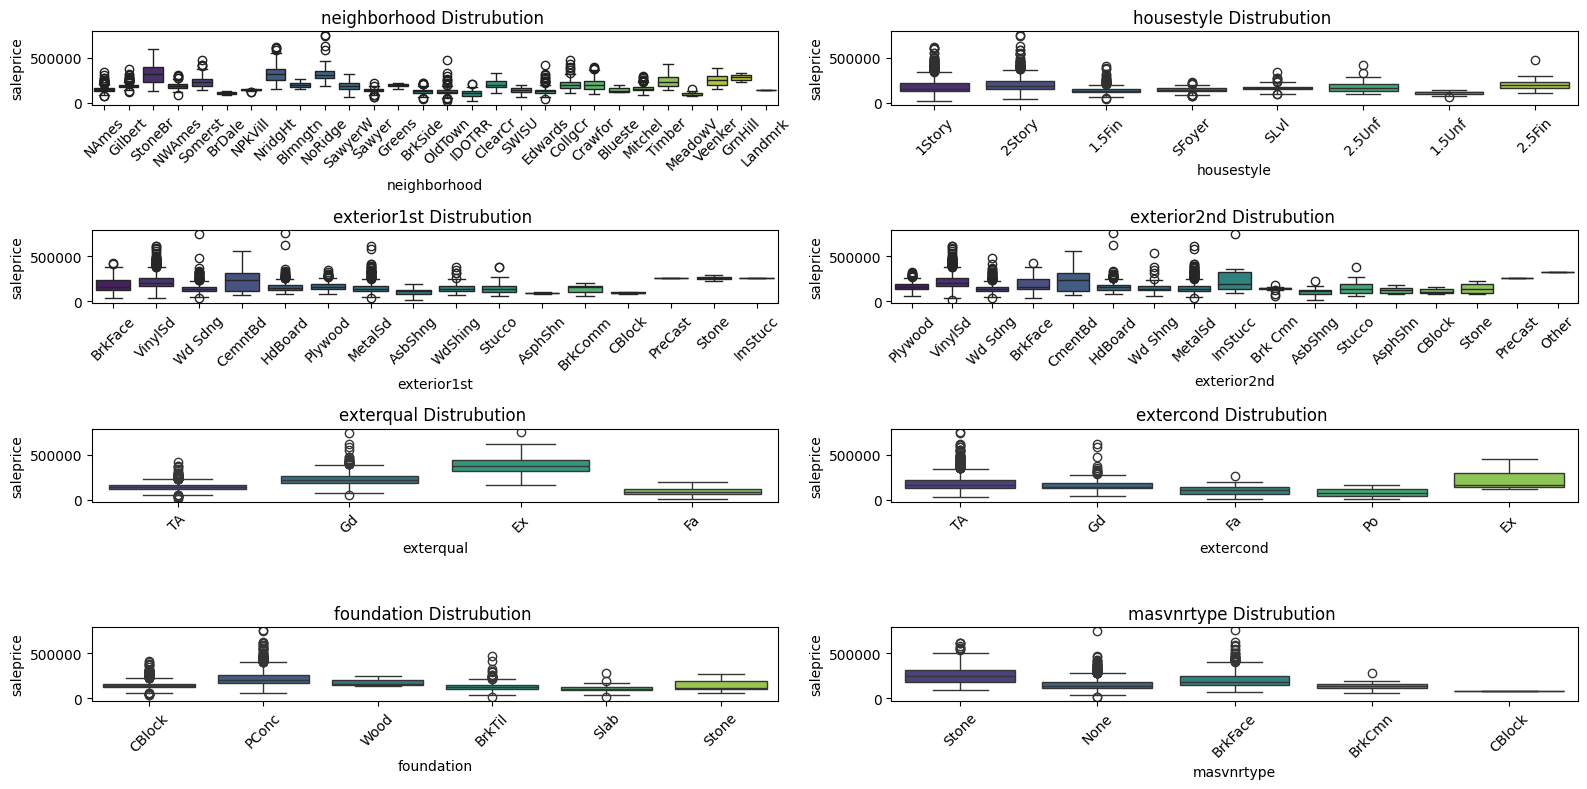

In [ ]:
columns_to_study=['neighborhood','housestyle','exterior1st','exterior2nd','exterqual','extercond','foundation','masvnrtype']
nfcol=2
nfrows=math.ceil(len(columns_to_study)/nfcol)
fig,ax=plt.subplots(nfrows,nfcol,
                    figsize=(16,nfcol*4))
ax=ax.flatten()
for i,col in enumerate(columns_to_study):
    sns.boxplot(data=df,
                x=col,
                y=df.saleprice,
                ax=ax[i],
                palette='viridis'
                )
    ax[i].set_title(f"{col} Distrubution ")
    ax[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
cat_df.drop(['exterior2nd','housestyle'],axis=1,inplace=True)
cat_df

,neighborhood,exterior1st,masvnrtype,exterqual,foundation,bsmtqual,bsmtfintype1,heatingqc,kitchenqual,fireplacequ,garagetype,garagefinish,paveddrive,poolqc
0,NAmes,BrkFace,Stone,TA,CBlock,TA,BLQ,Fa,TA,Gd,Attchd,Fin,P,NaN
1,NAmes,VinylSd,NaN,TA,CBlock,TA,Rec,TA,TA,NaN,Attchd,Unf,Y,NaN
2,NAmes,Wd Sdng,BrkFace,TA,CBlock,TA,ALQ,TA,Gd,NaN,Attchd,Unf,Y,NaN
3,NAmes,BrkFace,NaN,Gd,CBlock,TA,ALQ,Ex,Ex,TA,Attchd,Fin,Y,NaN
4,Gilbert,VinylSd,NaN,TA,PConc,Gd,GLQ,Gd,TA,TA,Attchd,Fin,Y,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Mitchel,HdBoard,NaN,TA,CBlock,TA,GLQ,TA,TA,NaN,Detchd,Unf,Y,NaN
2926,Mitchel,HdBoard,NaN,TA,CBlock,Gd,BLQ,TA,TA,NaN,Attchd,Unf,Y,NaN
2927,Mitchel,HdBoard,NaN,TA,PConc,Gd,GLQ,TA,TA,NaN,NaN,NaN,Y,NaN
2928,Mitchel,HdBoard,NaN,TA,CBlock,Gd,ALQ,Gd,TA,TA,Attchd,RFn,Y,NaN


In [ ]:
df.poolqc.value_counts()
df.poolarea.value_counts()

,count
poolarea,
0,2917
144,1
480,1
576,1
555,1
368,1
444,1
228,1
561,1


**Reason for Removal:**

Based on research into Iowa's cold winters, swimming pools may be less practical for year-round use and can require additional maintenance and winterization costs. In this preliminary analysis, `PoolQC` and `PoolArea` were selected for removal because swimming pool features may provide limited predictive value for residential property prices in this climate, while pool maintenance and winterization can add costs for homeowners.

However, the assumption that pools reduce property values has not been established for this dataset and should be validated through exploratory analysis and model evaluation.

In [ ]:
cat_df.drop(['poolqc'],axis=1,inplace=True)
cat_df

,neighborhood,exterior1st,masvnrtype,exterqual,foundation,bsmtqual,bsmtfintype1,heatingqc,kitchenqual,fireplacequ,garagetype,garagefinish,paveddrive
0,NAmes,BrkFace,Stone,TA,CBlock,TA,BLQ,Fa,TA,Gd,Attchd,Fin,P
1,NAmes,VinylSd,NaN,TA,CBlock,TA,Rec,TA,TA,NaN,Attchd,Unf,Y
2,NAmes,Wd Sdng,BrkFace,TA,CBlock,TA,ALQ,TA,Gd,NaN,Attchd,Unf,Y
3,NAmes,BrkFace,NaN,Gd,CBlock,TA,ALQ,Ex,Ex,TA,Attchd,Fin,Y
4,Gilbert,VinylSd,NaN,TA,PConc,Gd,GLQ,Gd,TA,TA,Attchd,Fin,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Mitchel,HdBoard,NaN,TA,CBlock,TA,GLQ,TA,TA,NaN,Detchd,Unf,Y
2926,Mitchel,HdBoard,NaN,TA,CBlock,Gd,BLQ,TA,TA,NaN,Attchd,Unf,Y
2927,Mitchel,HdBoard,NaN,TA,PConc,Gd,GLQ,TA,TA,NaN,NaN,NaN,Y
2928,Mitchel,HdBoard,NaN,TA,CBlock,Gd,ALQ,Gd,TA,TA,Attchd,RFn,Y


In [ ]:
df.paveddrive.value_counts()

,count
paveddrive,
Y,2652
N,216
P,62


<Axes: xlabel='paveddrive', ylabel='saleprice'>

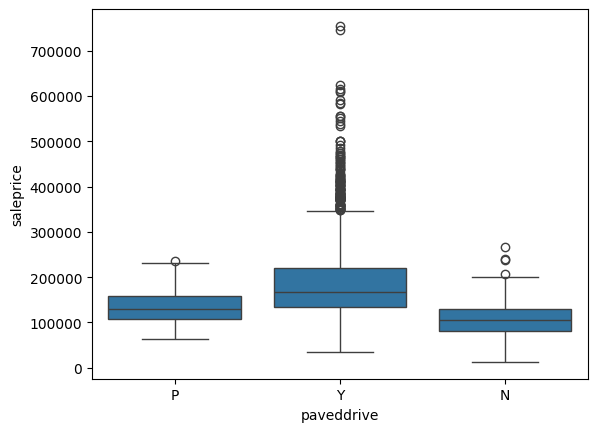

In [ ]:
sns.boxplot(data=df,x=df.paveddrive,y=df.saleprice)

In [ ]:
df.groupby('paveddrive')['saleprice'].agg(
    ['count','mean','median','std']
)

,count,mean,median,std
paveddrive,,,,
N,216,107224.236111,105500.0,39794.637616
P,62,134782.322581,129200.0,39306.746770
Y,2652,187864.071267,168000.0,79665.678766


In [ ]:
pd.crosstab(df['neighborhood'], df['paveddrive'], normalize='index') * 100

paveddrive,N,P,Y
neighborhood,,,
Blmngtn,0.000000,0.000000,100.000000
Blueste,0.000000,0.000000,100.000000
BrDale,3.333333,0.000000,96.666667
BrkSide,15.740741,10.185185,74.074074
ClearCr,6.818182,0.000000,93.181818
CollgCr,0.000000,0.000000,100.000000
Crawfor,3.883495,6.796117,89.320388
Edwards,17.525773,7.216495,75.257732
Gilbert,0.606061,1.818182,97.575758


In [ ]:
cat_df.drop(['paveddrive'],axis=1,inplace=True)
cat_df

,neighborhood,exterior1st,masvnrtype,exterqual,foundation,bsmtqual,bsmtfintype1,heatingqc,kitchenqual,fireplacequ,garagetype,garagefinish
0,NAmes,BrkFace,Stone,TA,CBlock,TA,BLQ,Fa,TA,Gd,Attchd,Fin
1,NAmes,VinylSd,NaN,TA,CBlock,TA,Rec,TA,TA,NaN,Attchd,Unf
2,NAmes,Wd Sdng,BrkFace,TA,CBlock,TA,ALQ,TA,Gd,NaN,Attchd,Unf
3,NAmes,BrkFace,NaN,Gd,CBlock,TA,ALQ,Ex,Ex,TA,Attchd,Fin
4,Gilbert,VinylSd,NaN,TA,PConc,Gd,GLQ,Gd,TA,TA,Attchd,Fin
...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Mitchel,HdBoard,NaN,TA,CBlock,TA,GLQ,TA,TA,NaN,Detchd,Unf
2926,Mitchel,HdBoard,NaN,TA,CBlock,Gd,BLQ,TA,TA,NaN,Attchd,Unf
2927,Mitchel,HdBoard,NaN,TA,PConc,Gd,GLQ,TA,TA,NaN,NaN,NaN
2928,Mitchel,HdBoard,NaN,TA,CBlock,Gd,ALQ,Gd,TA,TA,Attchd,RFn


## At a certain  catigorical stage
I identified 12 features that cover the following aspects:
Neighborhood: The most significant real estate factor.
Kitchen: `kitchenqual` (one of the most influential features in buyers' decision-making).
Structure and Foundation: `foundation`, `exterqual`, `exterior1st`, and `masvnrtype`.
Basement: `bsmtqual` and `bsmtfintype1` (covering quality and finish).
Warmth and Climate (relevant to Iowa winters): `heatingqc` and `fireplacequ`.
Garage: `garagetype` and `garagefinish` (focusing solely on type and finish, excluding extraneous details).

## Numerical Stage

In [ ]:
num_df


,order,pid,mssubclass,lotfrontage,lotarea,overallqual,overallcond,yearbuilt,yearremod/add,masvnrarea,...,wooddecksf,openporchsf,enclosedporch,3ssnporch,screenporch,poolarea,miscval,mosold,yrsold,saleprice
0,1,526301100,20,141.0,31770,6,5,1960,1960,112.0,...,210,62,0,0,0,0,0,5,2010,215000
1,2,526350040,20,80.0,11622,5,6,1961,1961,0.0,...,140,0,0,0,120,0,0,6,2010,105000
2,3,526351010,20,81.0,14267,6,6,1958,1958,108.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,4,526353030,20,93.0,11160,7,5,1968,1968,0.0,...,0,0,0,0,0,0,0,4,2010,244000
4,5,527105010,60,74.0,13830,5,5,1997,1998,0.0,...,212,34,0,0,0,0,0,3,2010,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,37.0,7937,6,6,1984,1984,0.0,...,120,0,0,0,0,0,0,3,2006,142500
2926,2927,923276100,20,NaN,8885,5,5,1983,1983,0.0,...,164,0,0,0,0,0,0,6,2006,131000
2927,2928,923400125,85,62.0,10441,5,5,1992,1992,0.0,...,80,32,0,0,0,0,700,7,2006,132000
2928,2929,924100070,20,77.0,10010,5,5,1974,1975,0.0,...,240,38,0,0,0,0,0,4,2006,170000


In [ ]:
null_numpercentage = (num_df.isna().sum() / len(num_df)) * 100

null_numcolumns_sorted = (null_numpercentage[null_numpercentage > 0].sort_values(ascending=False))

null_numcolumns_sorted

,0
lotfrontage,16.723549
garageyrblt,5.426621
masvnrarea,0.784983
bsmthalfbath,0.068259
bsmtfullbath,0.068259
bsmtfinsf1,0.034130
bsmtfinsf2,0.034130
totalbsmtsf,0.034130
bsmtunfsf,0.034130
garagecars,0.034130


/tmp/ipykernel_2675/518282649.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=null_numcolumns_sorted.values,y=null_numcolumns_sorted.index,palette='viridis')


<Axes: ylabel='None'>

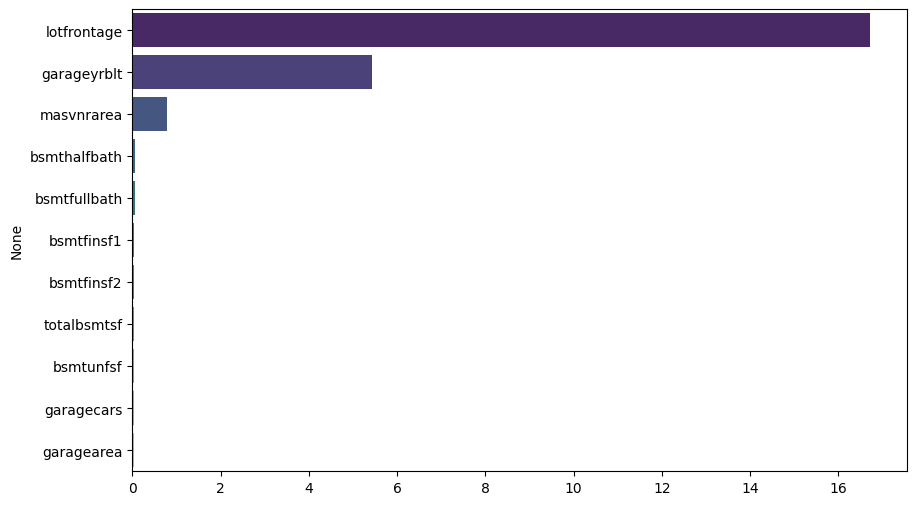

In [ ]:
fig,ax=plt.subplots(figsize=(10,6))
sns.barplot(x=null_numcolumns_sorted.values,y=null_numcolumns_sorted.index,palette='viridis')

In [ ]:
df.lotfrontage.value_counts()

,count
lotfrontage,
60.0,276
80.0,137
70.0,133
50.0,117
75.0,105
...,...
168.0,1
111.0,1
131.0,1


In [ ]:
num_df.drop('lotfrontage',axis=1,inplace=True)
num_df

,order,pid,mssubclass,lotarea,overallqual,overallcond,yearbuilt,yearremod/add,masvnrarea,bsmtfinsf1,...,wooddecksf,openporchsf,enclosedporch,3ssnporch,screenporch,poolarea,miscval,mosold,yrsold,saleprice
0,1,526301100,20,31770,6,5,1960,1960,112.0,639.0,...,210,62,0,0,0,0,0,5,2010,215000
1,2,526350040,20,11622,5,6,1961,1961,0.0,468.0,...,140,0,0,0,120,0,0,6,2010,105000
2,3,526351010,20,14267,6,6,1958,1958,108.0,923.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,4,526353030,20,11160,7,5,1968,1968,0.0,1065.0,...,0,0,0,0,0,0,0,4,2010,244000
4,5,527105010,60,13830,5,5,1997,1998,0.0,791.0,...,212,34,0,0,0,0,0,3,2010,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,7937,6,6,1984,1984,0.0,819.0,...,120,0,0,0,0,0,0,3,2006,142500
2926,2927,923276100,20,8885,5,5,1983,1983,0.0,301.0,...,164,0,0,0,0,0,0,6,2006,131000
2927,2928,923400125,85,10441,5,5,1992,1992,0.0,337.0,...,80,32,0,0,0,0,700,7,2006,132000
2928,2929,924100070,20,10010,5,5,1974,1975,0.0,1071.0,...,240,38,0,0,0,0,0,4,2006,170000


In [ ]:
num_df.drop(['garageyrblt','garagecars'],axis=1,inplace=True)
num_df

,order,pid,mssubclass,lotarea,overallqual,overallcond,yearbuilt,yearremod/add,masvnrarea,bsmtfinsf1,...,wooddecksf,openporchsf,enclosedporch,3ssnporch,screenporch,poolarea,miscval,mosold,yrsold,saleprice
0,1,526301100,20,31770,6,5,1960,1960,112.0,639.0,...,210,62,0,0,0,0,0,5,2010,215000
1,2,526350040,20,11622,5,6,1961,1961,0.0,468.0,...,140,0,0,0,120,0,0,6,2010,105000
2,3,526351010,20,14267,6,6,1958,1958,108.0,923.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,4,526353030,20,11160,7,5,1968,1968,0.0,1065.0,...,0,0,0,0,0,0,0,4,2010,244000
4,5,527105010,60,13830,5,5,1997,1998,0.0,791.0,...,212,34,0,0,0,0,0,3,2010,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,7937,6,6,1984,1984,0.0,819.0,...,120,0,0,0,0,0,0,3,2006,142500
2926,2927,923276100,20,8885,5,5,1983,1983,0.0,301.0,...,164,0,0,0,0,0,0,6,2006,131000
2927,2928,923400125,85,10441,5,5,1992,1992,0.0,337.0,...,80,32,0,0,0,0,700,7,2006,132000
2928,2929,924100070,20,10010,5,5,1974,1975,0.0,1071.0,...,240,38,0,0,0,0,0,4,2006,170000


In [ ]:
num_df[['totalbsmtsf', 'saleprice']].corr()

,totalbsmtsf,saleprice
totalbsmtsf,1.00000,0.63228
saleprice,0.63228,1.00000


<Axes: xlabel='totalbsmtsf', ylabel='saleprice'>

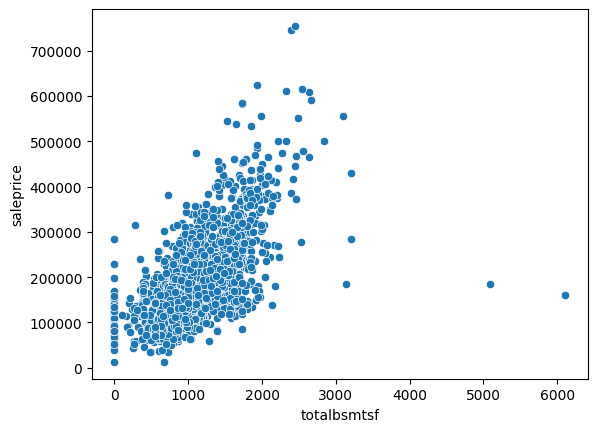

In [ ]:
sns.scatterplot(data=df,x=df.totalbsmtsf,y=df.saleprice)

In [ ]:
df = df.drop(df[(df['totalbsmtsf'] > 4000) & (df['saleprice'] < 200000)].index)

<Axes: xlabel='totalbsmtsf', ylabel='saleprice'>

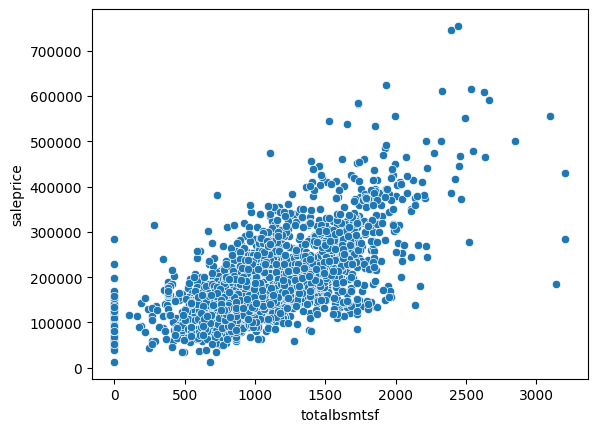

In [ ]:
sns.scatterplot(data=df,x=df.totalbsmtsf,y=df.saleprice)

In [ ]:
num_df[['bsmtfullbath', 'saleprice']].corr()

,bsmtfullbath,saleprice
bsmtfullbath,1.00000,0.27605
saleprice,0.27605,1.00000


In [ ]:
num_df[['bsmthalfbath', 'saleprice']].corr()

,bsmthalfbath,saleprice
bsmthalfbath,1.000000,-0.035835
saleprice,-0.035835,1.000000


In [ ]:
num_df.drop(['bsmtfinsf1','bsmtfinsf2','bsmtunfsf','bsmthalfbath','bsmtfullbath'],axis=1,inplace=True)
num_df

,order,pid,mssubclass,lotarea,overallqual,overallcond,yearbuilt,yearremod/add,masvnrarea,totalbsmtsf,...,wooddecksf,openporchsf,enclosedporch,3ssnporch,screenporch,poolarea,miscval,mosold,yrsold,saleprice
0,1,526301100,20,31770,6,5,1960,1960,112.0,1080.0,...,210,62,0,0,0,0,0,5,2010,215000
1,2,526350040,20,11622,5,6,1961,1961,0.0,882.0,...,140,0,0,0,120,0,0,6,2010,105000
2,3,526351010,20,14267,6,6,1958,1958,108.0,1329.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,4,526353030,20,11160,7,5,1968,1968,0.0,2110.0,...,0,0,0,0,0,0,0,4,2010,244000
4,5,527105010,60,13830,5,5,1997,1998,0.0,928.0,...,212,34,0,0,0,0,0,3,2010,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,7937,6,6,1984,1984,0.0,1003.0,...,120,0,0,0,0,0,0,3,2006,142500
2926,2927,923276100,20,8885,5,5,1983,1983,0.0,864.0,...,164,0,0,0,0,0,0,6,2006,131000
2927,2928,923400125,85,10441,5,5,1992,1992,0.0,912.0,...,80,32,0,0,0,0,700,7,2006,132000
2928,2929,924100070,20,10010,5,5,1974,1975,0.0,1389.0,...,240,38,0,0,0,0,0,4,2006,170000


### Feature Selection: Basement Attributes Consolidation
**Decision:**
* **Retain:** `TotalBsmtSF`
* **Drop:** `BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF`, `BsmtFullBath`, `BsmtHalfBath`

**Rationale:**
1. **Perfect Multicollinearity (Sub-areas):**
   By structural definition:
   $$\text{TotalBsmtSF} = \text{BsmtFinSF1} + \text{BsmtFinSF2} + \text{BsmtUnfSF}$$
   Keeping both the sub-components and the total area introduces exact linear dependency, causing ill-conditioned matrices and unstable coefficients in Linear Regression.
2. **Preserving Primary Signal:** `TotalBsmtSF` holds the strongest correlation ($r \approx 0.61$) with `SalePrice`. The qualitative finish status is already captured by our categorical feature `BsmtFinType1`.
3. **Negligible Predictive Power (Basement Bathrooms):**
   * **`BsmtHalfBath`** shows virtually **zero correlation** with `SalePrice` ($r \approx -0.016$) and suffers from extreme imbalance (over 95% are 0).
   * **`BsmtFullBath`** exhibits very weak correlation and high sparsity, adding little to no distinct signal beyond the main above-ground bathrooms (`FullBath`).

**Conclusion:** Dropping these 5 columns eliminates severe multicollinearity and removes uninformative dimensions without sacrificing predictive accuracy.

In [ ]:
df[['masvnrarea','saleprice']].corr()

,masvnrarea,saleprice
masvnrarea,1.000000,0.513357
saleprice,0.513357,1.000000


<Axes: xlabel='masvnrarea', ylabel='saleprice'>

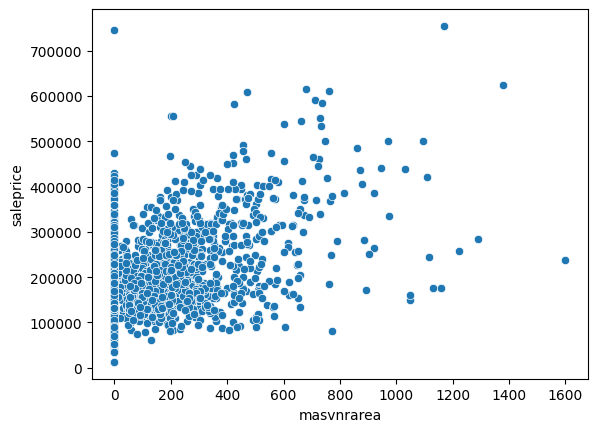

In [ ]:
sns.scatterplot(data=df,x=df.masvnrarea,y=df.saleprice)

In [ ]:
price_corr = df.corr(numeric_only=True)['saleprice'].sort_values()
print(price_corr)

pid             -0.246535
enclosedporch   -0.128822
kitchenabvgr    -0.119833
overallcond     -0.101745
mssubclass      -0.085087
lowqualfinsf    -0.037668
bsmthalfbath    -0.035999
order           -0.031420
yrsold          -0.030549
miscval         -0.019312
bsmtfinsf2       0.005869
3ssnporch        0.032217
mosold           0.035104
poolarea         0.071843
screenporch      0.112134
bedroomabvgr     0.143971
bsmtunfsf        0.182869
2ndflrsf         0.269637
lotarea          0.269900
bsmtfullbath     0.276784
halfbath         0.285302
openporchsf      0.316174
wooddecksf       0.327954
lotfrontage      0.367084
bsmtfinsf1       0.448782
fireplaces       0.476365
totrmsabvgrd     0.499325
masvnrarea       0.513357
garageyrblt      0.527376
yearremod/add    0.533312
fullbath         0.545784
yearbuilt        0.558805
1stflrsf         0.642666
garagearea       0.643996
garagecars       0.648192
totalbsmtsf      0.657944
grlivarea        0.722095
overallqual      0.801582
saleprice   

In [ ]:
num_cols_to_drop = [
    'order', 'pid','yrsold', 'mosold', 'miscval', 'lowqualfinsf', '3ssnporch', 'poolarea', 'mssubclass','kitchenabvgr', 'enclosedporch', 'overallcond']
num_df.drop(num_cols_to_drop,axis=1,inplace=True)
num_df

,lotarea,overallqual,yearbuilt,yearremod/add,masvnrarea,totalbsmtsf,1stflrsf,2ndflrsf,grlivarea,fullbath,halfbath,bedroomabvgr,totrmsabvgrd,fireplaces,garagearea,wooddecksf,openporchsf,screenporch,saleprice
0,31770,6,1960,1960,112.0,1080.0,1656,0,1656,1,0,3,7,2,528.0,210,62,0,215000
1,11622,5,1961,1961,0.0,882.0,896,0,896,1,0,2,5,0,730.0,140,0,120,105000
2,14267,6,1958,1958,108.0,1329.0,1329,0,1329,1,1,3,6,0,312.0,393,36,0,172000
3,11160,7,1968,1968,0.0,2110.0,2110,0,2110,2,1,3,8,2,522.0,0,0,0,244000
4,13830,5,1997,1998,0.0,928.0,928,701,1629,2,1,3,6,1,482.0,212,34,0,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,7937,6,1984,1984,0.0,1003.0,1003,0,1003,1,0,3,6,0,588.0,120,0,0,142500
2926,8885,5,1983,1983,0.0,864.0,902,0,902,1,0,2,5,0,484.0,164,0,0,131000
2927,10441,5,1992,1992,0.0,912.0,970,0,970,1,0,3,6,0,0.0,80,32,0,132000
2928,10010,5,1974,1975,0.0,1389.0,1389,0,1389,1,0,2,6,1,418.0,240,38,0,170000


In [ ]:
price_corrnum = num_df.corr(numeric_only=True)['saleprice'].sort_values()
print(price_corrnum)

screenporch      0.112151
bedroomabvgr     0.143913
lotarea          0.266549
2ndflrsf         0.269373
halfbath         0.285056
openporchsf      0.312951
wooddecksf       0.327143
fireplaces       0.474558
totrmsabvgrd     0.495474
masvnrarea       0.508285
yearremod/add    0.532974
fullbath         0.545604
yearbuilt        0.558426
1stflrsf         0.621676
totalbsmtsf      0.632280
garagearea       0.640401
grlivarea        0.706780
overallqual      0.799262
saleprice        1.000000
Name: saleprice, dtype: float64


In [ ]:
corr_comparison = pd.DataFrame({
    'Pearson': num_df.corr(method='pearson', numeric_only=True)['saleprice'],
    'Spearman': num_df.corr(method='spearman', numeric_only=True)['saleprice']
})

corr_comparison['Diff (Spearman - Pearson)'] = corr_comparison['Spearman'] - corr_comparison['Pearson']
corr_comparison.sort_values(by='Diff (Spearman - Pearson)', ascending=False)

,Pearson,Spearman,Diff (Spearman - Pearson)
openporchsf,0.312951,0.479578,0.166628
lotarea,0.266549,0.429249,0.162700
yearbuilt,0.558426,0.680822,0.122396
fullbath,0.545604,0.634161,0.088557
yearremod/add,0.532974,0.601454,0.068480
bedroomabvgr,0.143913,0.196834,0.052921
fireplaces,0.474558,0.526137,0.051579
halfbath,0.285056,0.333657,0.048601
wooddecksf,0.327143,0.364185,0.037042
garagearea,0.640401,0.660676,0.020275


In [ ]:
num_df.drop(['screenporch'],axis=1,inplace=True)

In [ ]:
num_df

,lotarea,overallqual,yearbuilt,yearremod/add,masvnrarea,totalbsmtsf,1stflrsf,2ndflrsf,grlivarea,fullbath,halfbath,bedroomabvgr,totrmsabvgrd,fireplaces,garagearea,wooddecksf,openporchsf,saleprice
0,31770,6,1960,1960,112.0,1080.0,1656,0,1656,1,0,3,7,2,528.0,210,62,215000
1,11622,5,1961,1961,0.0,882.0,896,0,896,1,0,2,5,0,730.0,140,0,105000
2,14267,6,1958,1958,108.0,1329.0,1329,0,1329,1,1,3,6,0,312.0,393,36,172000
3,11160,7,1968,1968,0.0,2110.0,2110,0,2110,2,1,3,8,2,522.0,0,0,244000
4,13830,5,1997,1998,0.0,928.0,928,701,1629,2,1,3,6,1,482.0,212,34,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,7937,6,1984,1984,0.0,1003.0,1003,0,1003,1,0,3,6,0,588.0,120,0,142500
2926,8885,5,1983,1983,0.0,864.0,902,0,902,1,0,2,5,0,484.0,164,0,131000
2927,10441,5,1992,1992,0.0,912.0,970,0,970,1,0,3,6,0,0.0,80,32,132000
2928,10010,5,1974,1975,0.0,1389.0,1389,0,1389,1,0,2,6,1,418.0,240,38,170000


In [ ]:
features_corr = num_df.drop(columns=['saleprice']).corr(numeric_only=True)
mask = np.triu(np.ones(features_corr.shape, dtype=bool), k=1)
pairs = features_corr.where(mask).stack().reset_index()
pairs.columns = ['Feature 1', 'Feature 2', 'Corr']
pairs['abs'] = pairs['Corr'].abs()
strong_multicollinear = pairs[pairs['abs'] >= 0.50].sort_values(by='abs', ascending=False)
print(strong_multicollinear)

        Feature 1      Feature 2      Corr       abs
103     grlivarea   totrmsabvgrd  0.807772  0.807772
70    totalbsmtsf       1stflrsf  0.800720  0.800720
121  bedroomabvgr   totrmsabvgrd  0.672647  0.672647
91       2ndflrsf      grlivarea  0.655251  0.655251
100     grlivarea       fullbath  0.630321  0.630321
31      yearbuilt  yearremod/add  0.612095  0.612095
93       2ndflrsf       halfbath  0.611634  0.611634
16    overallqual      yearbuilt  0.597027  0.597027
95       2ndflrsf   totrmsabvgrd  0.585214  0.585214
22    overallqual      grlivarea  0.570556  0.570556
17    overallqual  yearremod/add  0.569609  0.569609
28    overallqual     garagearea  0.563503  0.563503
82       1stflrsf      grlivarea  0.562166  0.562166
19    overallqual    totalbsmtsf  0.547294  0.547294
110      fullbath   totrmsabvgrd  0.528599  0.528599
23    overallqual       fullbath  0.522263  0.522263
102     grlivarea   bedroomabvgr  0.516808  0.516808
94       2ndflrsf   bedroomabvgr  0.504651  0.

In [ ]:
num_df.drop(columns=['totrmsabvgrd', '1stflrsf'], inplace=True)
num_df

,lotarea,overallqual,yearbuilt,yearremod/add,masvnrarea,totalbsmtsf,2ndflrsf,grlivarea,fullbath,halfbath,bedroomabvgr,fireplaces,garagearea,wooddecksf,openporchsf,saleprice
0,31770,6,1960,1960,112.0,1080.0,0,1656,1,0,3,2,528.0,210,62,215000
1,11622,5,1961,1961,0.0,882.0,0,896,1,0,2,0,730.0,140,0,105000
2,14267,6,1958,1958,108.0,1329.0,0,1329,1,1,3,0,312.0,393,36,172000
3,11160,7,1968,1968,0.0,2110.0,0,2110,2,1,3,2,522.0,0,0,244000
4,13830,5,1997,1998,0.0,928.0,701,1629,2,1,3,1,482.0,212,34,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,7937,6,1984,1984,0.0,1003.0,0,1003,1,0,3,0,588.0,120,0,142500
2926,8885,5,1983,1983,0.0,864.0,0,902,1,0,2,0,484.0,164,0,131000
2927,10441,5,1992,1992,0.0,912.0,0,970,1,0,3,0,0.0,80,32,132000
2928,10010,5,1974,1975,0.0,1389.0,0,1389,1,0,2,1,418.0,240,38,170000


## Preprocessing Stage
Frist we will select choosen columns in ['catigorical','numrical']

In [ ]:
selected_columns = [
    'saleprice',

  #cat_df
    'neighborhood', 'exterior1st', 'masvnrtype', 'exterqual', 'foundation',
    'bsmtqual', 'bsmtfintype1', 'heatingqc', 'kitchenqual', 'fireplacequ',
    'garagetype', 'garagefinish',

    # num_df
    'overallqual', 'grlivarea', 'totalbsmtsf', 'garagearea',
    'yearbuilt', 'yearremod/add', 'fullbath', 'halfbath',
    'masvnrarea', 'fireplaces', 'wooddecksf', 'openporchsf',
    'lotarea', '2ndflrsf', 'bedroomabvgr'
]
df_clean = df[[col for col in selected_columns if col in df.columns]].copy()
print("Clean DataFrame Shape:", df_clean.shape)

Clean DataFrame Shape: (2928, 28)


## Filling the missing
columns with NONE in cat_columns and ZERO in num_col

In [ ]:
cat_cols = df_clean.select_dtypes(include=['object']).columns
df_clean[cat_cols] = df_clean[cat_cols].fillna('None')


num_cols = df_clean.select_dtypes(include=['number']).columns
df_clean[num_cols] = df_clean[num_cols].fillna(0)

print("Total Missing Values now:", df_clean.isnull().sum().sum())

Total Missing Values now: 0


## Splitting data to
x-data and y-target

In [ ]:
X = df_clean.drop(columns=['saleprice'])
y = df_clean['saleprice']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)




In [ ]:
quality_order = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
finish_order  = ['None', 'Unf', 'RFn', 'Fin']

ordinal_cols_quality = [col for col in ['exterqual', 'kitchenqual', 'bsmtqual', 'heatingqc', 'fireplacequ'] if col in X_train.columns]
ordinal_cols_finish  = [col for col in ['garagefinish'] if col in X_train.columns]

nominal_cols = [col for col in ['neighborhood', 'exterior1st', 'masvnrtype', 'foundation', 'bsmtfintype1', 'garagetype'] if col in X_train.columns]

numeric_cols = X_train.select_dtypes(include=['number']).columns.tolist()


preprocessor = ColumnTransformer(
    transformers=[

        ('num', StandardScaler(), numeric_cols),


        ('ord_qual', OrdinalEncoder(categories=[quality_order]*len(ordinal_cols_quality), handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols_quality),


        ('ord_finish', OrdinalEncoder(categories=[finish_order]*len(ordinal_cols_finish), handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols_finish),


        ('nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), nominal_cols)
    ]
)



In [ ]:
import numpy as np
from numpy.linalg import norm


def fdriv(X, w, t):
    N = X.shape[0]
    y_predict = X @ w
    error = y_predict - t
    return (1 / N) * (X.T @ error)


def costfun(X, w, t):
    N = X.shape[0]
    y_predict = X @ w
    error = y_predict - t
    return (1 / (2 * N)) * np.sum(error ** 2)

def gradient_descent(X, t, percision=0.0001, max_iter=1000, step_size=0.01):

    X = np.c_[np.ones(X.shape[0]), X]
    num_features = X.shape[1]


    curve_state = np.random.rand(num_features)
    last_state = curve_state + 100 * percision

    state_list = [curve_state.copy()]
    cost_history = [costfun(X, curve_state, t)]

    it = 0

    while norm(curve_state - last_state) > percision and it < max_iter:
        last_state = curve_state.copy()
        grad = fdriv(X, curve_state, t)
        curve_state = curve_state - (step_size * grad)

        state_list.append(curve_state.copy())
        cost_history.append(costfun(X, curve_state, t))
        it += 1

    return curve_state, cost_history

In [ ]:
from sklearn.preprocessing import StandardScaler
scale=StandardScaler()
y_train_scaled=scale.fit_transform(
    y_train.values.reshape(-1,1)
    ).flatten()

In [ ]:
from sklearn.base import BaseEstimator,RegressorMixin
class CustomGradientDsescnt(BaseEstimator,RegressorMixin):
  def __init__(self,step_size=0.01,percision=0.0001,max_iter=1000):
    self.step_size=step_size
    self.percision=percision
    self.max_iter=int(max_iter)
    self.weights=None
    self.cost_history=[]
  def fit(self,X,y):
    self.weights,self.cost_history=gradient_descent(
        X,y,
        step_size=self.step_size,
        percision=self.percision,
        max_iter=self.max_iter
    )
    return self
  def predict(self,X):
      x_arr=np.array(X)
      X_with_base=np.c_[np.ones(x_arr.shape[0]),X]
      return X_with_base @ self.weights

In [ ]:
gradientPipLine=Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("model",CustomGradientDsescnt(step_size=0.01,percision=0.0001,max_iter=1000))
])


In [ ]:
print("Training Custom Gradient Descent Pipeline...")
gradientPipLine.fit(X_train,y_train_scaled)

Training Custom Gradient Descent Pipeline...


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['overallqual', 'grlivarea',
                                                   'totalbsmtsf', 'garagearea',
                                                   'yearbuilt', 'yearremod/add',
                                                   'fullbath', 'halfbath',
                                                   'masvnrarea', 'fireplaces',
                                                   'wooddecksf', 'openporchsf',
                                                   'lotarea', '2ndflrsf',
                                                   'bedroomabvgr']),
                                                 ('ord_qual',
                                                  OrdinalEncoder(categories=[['None',
                                                                              'Po',
                                                                              'Fa',
                                                                              'TA',
                                                                              'Gd',...
                                                   'fireplacequ']),
                                                 ('ord_finish',
                                                  OrdinalEncoder(categories=[['None',
                                                                              'Unf',
                                                                              'RFn',
                                                                              'Fin']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['garagefinish']),
                                                 ('nom',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['neighborhood',
                                                   'exterior1st', 'masvnrtype',
                                                   'foundation', 'bsmtfintype1',
                                                   'garagetype'])])),
                ('model', CustomGradientDsescnt())])

In [ ]:
print("Weights are:", gradientPipLine.named_steps['model'].weights)

Weights are: [ 0.33217713  0.42316574  0.26573168  0.30801941  0.1231771   0.25971626
  0.20029879 -0.03117398  0.01879499  0.15260187  0.13568842  0.07608443
  0.04046671  0.07847234  0.04715131 -0.08614159 -0.4566801  -0.00781252
 -0.18287189 -0.06878229 -0.03333358 -0.01710056  0.41824446  0.49370514
  0.39305949  0.06229847  0.58673302  0.66301269  0.27862486  0.61168516
  0.66101155  0.34486898  0.75368661  0.02603167  0.61873227  0.49889683
  0.23396871  0.8527116   0.19718247  0.51925594  0.33604355  0.66871521
  0.62562161  0.32080824  0.30810375  0.23828932  0.39228214  0.43210566
  0.11674423  0.15618848  0.98593322  0.76867106  0.24398184  0.36713653
  0.36380928  0.66160627  0.63188485  0.50282501  0.98531538  0.83356717
  0.87581697  0.4314977   0.572681    0.65133945  0.3687043   0.81830657
  0.52948978  0.44214621  0.07732218  0.07860674  0.37964609  0.03239374
  0.3447848   0.71878244  0.60640022  0.72651232  0.58113519  0.5982835
  0.43986744  0.31938307  0.09496751  0

In [ ]:
y_scaled_predicted=gradientPipLine.predict(X_test)
from sklearn.metrics import mean_squared_error
y_test_scaled = scale.transform(y_test.values.reshape(-1, 1)).flatten()
mse_scaled=mean_squared_error(y_test_scaled,y_scaled_predicted)
print(f"Men Square Error = {mse_scaled}")

Men Square Error = 0.38776837321515734


/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


In [ ]:
y_dollar_predicted=scale.inverse_transform(y_scaled_predicted.reshape(-1,1)).flatten()
mse_dollar=mean_squared_error(y_test,y_dollar_predicted)
rmse_dollar=np.sqrt(mse_dollar)
print(rmse_dollar)

47849.709360193156


In [ ]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_dollar_predicted)
print(f"الموديل يفسر حوالي {r2 * 100:.2f}% من التغير في أسعار البيوت.")

الموديل يفسر حوالي 72.39% من التغير في أسعار البيوت.


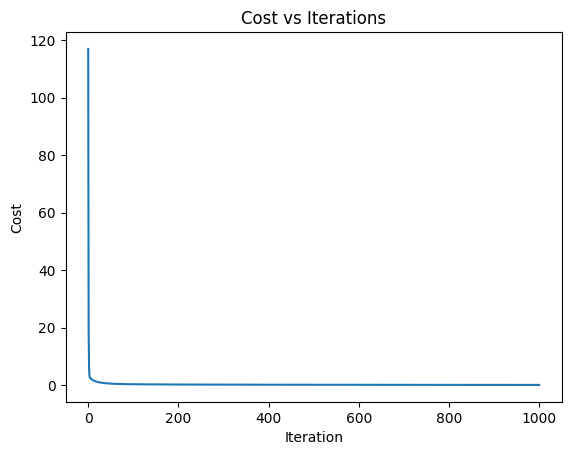

In [ ]:
import matplotlib.pyplot as plt

plt.plot(gradientPipLine.named_steps['model'].cost_history)
plt.title("Cost vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()

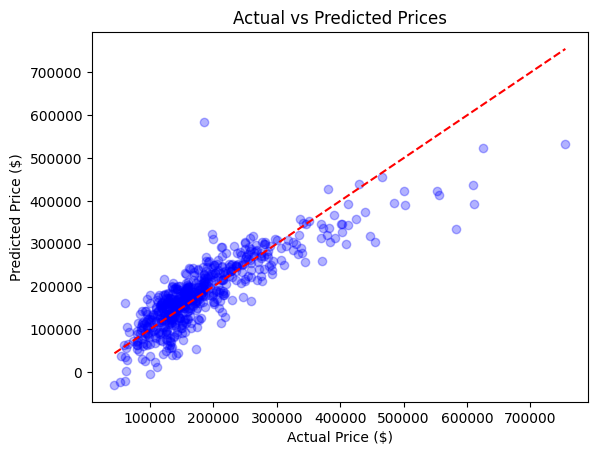

In [ ]:
plt.scatter(y_test, y_dollar_predicted, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--') # خط الكمال 45 درجة
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Prices")
plt.show()

In [ ]:
def get_metrics(model, X_train, y_train, X_test, y_test):
    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    return {
        'Train R²': r2_score(y_train, train_pred),
        'Test R²': r2_score(y_test, test_pred),
        'Test RMSE ($)': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test MAE ($)': mean_absolute_error(y_test, test_pred)
    }


results = {
    'Linear Regression': get_metrics(lr_pipeline, X_train, y_train, X_test, y_test),
    'Random Forest': get_metrics(rf_pipeline, X_train, y_train, X_test, y_test)
}

results_df = pd.DataFrame(results).T
results_df['Train R²'] = results_df['Train R²'].map('{:.4f}'.format)
results_df['Test R²'] = results_df['Test R²'].map('{:.4f}'.format)
results_df['Test RMSE ($)'] = results_df['Test RMSE ($)'].map('${:,.2f}'.format)
results_df['Test MAE ($)'] = results_df['Test MAE ($)'].map('${:,.2f}'.format)

results_df

NameError: name 'lr_pipeline' is not defined

In [ ]:

feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()


clean_feature_names = [
    col.replace('num__', '').replace('ord_qual__', '').replace('ord_finish__', '').replace('nom__', '')
    for col in feature_names
]


importances = rf_pipeline.named_steps['model'].feature_importances_


feat_imp = pd.Series(importances, index=clean_feature_names).sort_values(ascending=False).head(12)


plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')
plt.title('Top 12 Most Important Features Predicting House Prices (Random Forest)', fontsize=14, weight='bold')
plt.xlabel('Relative Feature Importance', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
%pip install xgboost

In [ ]:

from sklearn.linear_model import LinearRegression, Lasso
from xgboost import XGBRegressor

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])


lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=50.0, random_state=42, max_iter=10000))
])

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42, n_jobs=-1))
])


lr_pipeline.fit(X_train, y_train)


lasso_pipeline.fit(X_train, y_train)


xgb_pipeline.fit(X_train, y_train)



In [ ]:
def get_metrics(model, X_train, y_train, X_test, y_test):
    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    return {
        'Train R²': r2_score(y_train, train_pred),
        'Test R²': r2_score(y_test, test_pred),
        'Test RMSE ($)': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test MAE ($)': mean_absolute_error(y_test, test_pred)
    }


results = {
    'Linear Regression': get_metrics(lr_pipeline, X_train, y_train, X_test, y_test),
    'Lasso Regression':  get_metrics(lasso_pipeline, X_train, y_train, X_test, y_test),
    'XGBoost':           get_metrics(xgb_pipeline, X_train, y_train, X_test, y_test)
}


results_df = pd.DataFrame(results).T
results_df['Train R²'] = results_df['Train R²'].map('{:.4f}'.format)
results_df['Test R²'] = results_df['Test R²'].map('{:.4f}'.format)
results_df['Test RMSE ($)'] = results_df['Test RMSE ($)'].map('${:,.2f}'.format)
results_df['Test MAE ($)'] = results_df['Test MAE ($)'].map('${:,.2f}'.format)

results_df

In [ ]:
feature_names = xgb_pipeline.named_steps['preprocessor'].get_feature_names_out()
clean_feature_names = [
    col.replace('num__', '').replace('ord_qual__', '').replace('ord_finish__', '').replace('nom__', '')
    for col in feature_names
]


importances = xgb_pipeline.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=clean_feature_names).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='mako')
plt.title('Top 12 Most Important Features (XGBoost)', fontsize=14, weight='bold')
plt.xlabel('Relative Feature Importance (Gain)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()